## Used Car Price Prediction - Machine Learning

### Objective

The objective of this project is to build a machine learning model that predicts the selling price of a used car based on its characteristics such as brand, model, variant, age, mileage, fuel type, transmission, engine capacity, etc.

### Target Variable

- Target: `price`
- Problem Type: Supervised Learning
- ML Task: Regression

In [3]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import importlib, joblib
import utils
importlib.reload(utils)
from utils import check_inconsistency, fill_missing_values
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import (mean_absolute_error, median_absolute_error, mean_squared_error, 
                             root_mean_squared_error, r2_score, root_mean_squared_log_error)
from sklearn.model_selection import cross_val_score, cross_validate, RandomizedSearchCV

### Prepare the final Dataset

The final dataset is created by combining four used-car datasets, which were cleaned and standardized into same format.
The dataset contains:
- Numerical features
- Categorical features
- Vehicle specifications
- Target variable: price

In [4]:
# Load all the datasets
df1 = pd.read_csv(r'.\Cleaned Datasets\dataset_1.csv')
df2 = pd.read_csv(r'.\Cleaned Datasets\dataset_2.csv')
df3 = pd.read_csv(r'.\Cleaned Datasets\dataset_3.csv')
df4 = pd.read_csv(r'.\Cleaned Datasets\dataset_4.csv')

In [5]:
# Print the shape of the all the datasets
print("Dataset-1:", df1.shape)
print("Dataset-2:", df2.shape)
print("Dataset-3:", df3.shape)
print("Dataset-4:", df4.shape)

Dataset-1: (2805, 34)
Dataset-2: (1445, 34)
Dataset-3: (14989, 34)
Dataset-4: (37810, 34)


In [6]:
# Concatenate all the datasets and validate the shape of the final dataset
df = pd.concat([df1, df2, df3, df4])
print("Final Dataset:", df.shape)

Final Dataset: (57049, 34)


The final dataset contains a total of around 57k records for analysis and build the ML algorithm.

In [7]:
# Convert all the values to upper case in order to maintain consistency
df = df.apply(lambda x: x.str.upper() if (x.dtype=='object' or x.dtype=='str') else x)

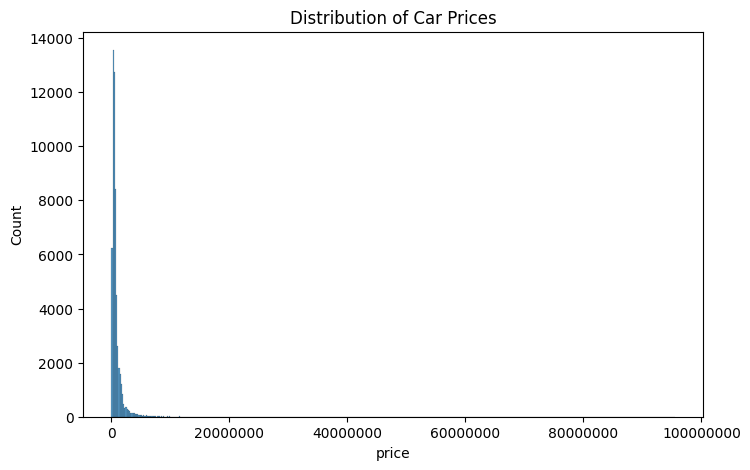

In [6]:
# Understand the Target Variable
plt.figure(figsize=(8,5))
sns.histplot(data=df, x='price')
plt.title('Distribution of Car Prices')
plt.ticklabel_format(style='plain', axis='x')
plt.show()

The car-price distribution is highly right-skewed, with most vehicles concentrated in the lower price range and a relatively small number of high-priced vehicles forming a long upper tail. Although these observations are identified as outliers by the IQR-based box plot, validation confirms that they are legitimate records, most likely representing premium or luxury vehicles.

In [8]:
# Check the 5 most expensive cars
df.nlargest(5, 'price')[['brand', 'model', 'variant', 'make_year', 'price']]

,brand,model,variant,make_year,price
13637,ROLLS-ROYCE,PHANTOM,EXTENDED WHEELBASE,2021.0,95519530.0
2766,FERRARI,SF90 STRADALE,V8,2022.0,44425000.0
3330,ROLLS-ROYCE,PHANTOM SERIES II,EWB,2015.0,42527500.0
12681,LAMBORGHINI,URUS,NaN,2021.0,39006400.0
13282,MERCEDES-BENZ,G CLASS,AMG 63,2023.0,34810800.0


The above cars are luxury cars and these usualy are priced higher than the mass market cars. The above data seems correct and not erronous.

In [9]:
# Check the 5 cheapest cars
df.nsmallest(5, 'price')[['brand', 'model', 'variant', 'make_year', 'price']]

,brand,model,variant,make_year,price
1754,TATA,INDIGO MARINA,LX,2005.0,11963.0
1750,MAHINDRA,MARSHAL,NaN,2000.0,15800.0
10348,MARUTI SUZUKI,BREZZA,NaN,2023.0,15800.0
13581,BMW,5 SERIES,NaN,2014.0,15800.0
14438,RENAULT,DUSTER,NaN,2013.0,15800.0


A small number of vehicles are listed at extremely low prices (around ₹10,000–₹15,000), which appears unrealistic for the used-car market. These observations require further investigation and may need to be treated as erroneous records during data cleaning.

In [10]:
# Check the cars where price is less than Rs 50000
df[(df['price']<50000)&(df['make_year']>2010)&(df['model']!='NANO')][['brand', 'model', 'variant', 'make_year', 
                                                                      'price']]

,brand,model,variant,make_year,price
3033,MARUTI SUZUKI,BALENO,NaN,2024.0,19400.0
3905,MERCEDES-BENZ,GLS,NaN,2021.0,39900.0
7504,ASHOK,LEYLAND STILE,NaN,2024.0,33600.0
9089,KIA,CERATO,NaN,2024.0,47200.0
10348,MARUTI SUZUKI,BREZZA,NaN,2023.0,15800.0
11936,MAHINDRA,THAR ROXX,NaN,2024.0,22000.0
13186,HYUNDAI,ACCENT,NaN,2017.0,31500.0
13581,BMW,5 SERIES,NaN,2014.0,15800.0
13917,MARUTI SUZUKI,ALTO-K10,NaN,2021.0,18900.0
14021,MARUTI SUZUKI,SWIFT,NaN,2023.0,42000.0


The above data seems to be erronous and needs to be removed from the data set as any car which is manufactured after 2010 can't have price lesser than Rs 50000 except Tata Nano.

In [11]:
# Remove the erronous data listed above
df = df[~((df['price']<50000)&(df['make_year']>2010)&(df['model']!='NANO'))]

#### Standardization of brand, models and variants

In [12]:
# Check for the unique brands
df['brand'].unique()

<ArrowStringArray>
[     'MAHINDRA',       'HYUNDAI',          'TATA',         'HONDA',
          'FORD', 'MARUTI SUZUKI',           'KIA',            'MG',
       'RENAULT',    'VOLKSWAGEN',        'NISSAN',         'SKODA',
        'TOYOTA',        'DATSUN',          'JEEP',           'BMW',
 'MERCEDES-BENZ',          'AUDI',         'VOLVO',          'MINI',
    'LAND ROVER',     'CHEVROLET',        'JAGUAR',          'FIAT',
  'ASTON MARTIN',       'PORSCHE',         'FORCE',    'MITSUBISHI',
         'LEXUS',         'ISUZU',    'AMBASSADOR',   'ROLLS-ROYCE',
          'ICML',         'BAJAJ',          'OPEL',       'BENTLEY',
     'SSANGYONG',      'MASERATI',   'TOYOTA LAND',       'CITROEN',
   'LAMBORGHINI',        'HUMMER', 'ASHOK LEYLAND',       'FERRARI',
            'DC',       'PREMIER']
Length: 46, dtype: str

In [13]:
# Replace Ashok with Ashok Leyland and Toyota Land with Toyota
df['brand'] = df['brand'].replace({'ASHOK': 'ASHOK LEYLAND', 'TOYOTA LAND': 'TOYOTA'})

In [14]:
# Check for the unique models
df['model'].unique()

<ArrowStringArray>
[          'THAR',          'VERNA',        'HARRIER',           'CITY',
       'ECOSPORT',           'WR-V',          'PUNCH',          'NEXON',
         'XUV700',          'DZIRE',
 ...
 'ELITE I20 2018',         'ARMADA',      'BALENO RS',         'GHIBLI',
    'INDICA XETA',      'ALTO 2021',        'TOUAREG',         'WILLYS',
        'KIZASHI',      'TUV 300 +']
Length: 547, dtype: str

In [15]:
# Replace the models names which are duplicate eg: SWIFT DZIRE, SWIFT-DZIRE etc.
model_mapping = {'3 SERIES GRAN LIMOUSINE': '3 SERIES', '3 SERIES GT': '3 SERIES', '5 SERIES GT': '5 SERIES', 
                 '6 SERIES GT': '6 SERIES', '718 CAYMAN': '718', 'A CLASS': 'A-CLASS', 'A STAR': 'A-STAR', 
                 'A-CLASS LIMOUSINE': 'A-CLASS', 'A3 CABRIOLET': 'A3', 'A8 2010-2013': 'A8', 'A8 L': 'A8', 
                 'ACCENT HATCHBACK': 'ACCENT', 'ALTO 2021': 'ALTO-800', 'ALTO 800': 'ALTO-800', 
                 'ALTO K10': 'ALTO-K10', 'AMG A 35': 'A-35', 'AMG A35': 'A-35', 'AMG C 43': 'C-43', 
                 'AMG GLA 35': 'GLA', 'AMG GLE 53': 'GLE', 'AMG GLE COUPE': 'GLE', 'AVEO U-VA': 'AVEO', 
                 'AVVENTURA URBAN CROSS': 'AVVENTURA', 'BALENO RS': 'BALENO', 'BALENO-RS': 'BALENO', 
                 'BOLERO CAMPER': 'BOLERO-PICKUP', 'BOLERO MAXI TRUCK+': 'BOLERO-PICKUP', 
                 'BOLERO NEO': 'BOLERO-NEO', 'BOLERO NEO+': 'BOLERO-NEO', 
                 'BOLERO PIK UP EXTRA LONG': 'BOLERO-PICKUP', 'BOLERO PIK UP EXTRA STRONG': 'BOLERO-PICKUP', 
                 'BOLERO POWER+': 'BOLERO', 'BREZZA': 'VITARA-BREZZA', 'BRV': 'BR-V', 'C CLASS': 'C-CLASS', 
                 'CAYENNE COUPE': 'CAYENNE', 'CELERIO TOUR 2018-2021': 'CELERIO', 'CELERIO X': 'CELERIO', 
                 'CELERIO-X': 'CELERIO', 'CIAZ S': 'CIAZ', 'CITY HYBRID EHEV': 'CITY', 'CITY ZX': 'CITY', 
                 'COMPASS TRAILHAWK': 'COMPASS', 'CONTINENTAL': 'COMPASS', 'COOPER 3 DOOR': 'COOPER', 
                 'COOPER 5 DOOR': 'COOPER', 'COOPER CLUBMAN': 'COOPER', 'COOPER CONVERTIBLE': 'COOPER', 
                 'COOPER COUNTRYMAN': 'COOPER', 'COOPER S': 'COOPER', 'COOPER SE': 'COOPER', 
                 'COROLLA ALTIS': 'COROLLA', 'CRETA FACELIFT': 'CRETA', 'CROSSPOLO': 'POLO', 
                 'CRUISER PRADO': 'CRUISER', 'D-MAX V-CROSS': 'D-MAX', 'DISCOVERY SPORT': 'DISCOVERY', 
                 'DZIRE': 'SWIFT-DZIRE', 'E-CLASS ALL-TERRAIN': 'E-CLASS', 'E2O +': 'E2O', 'EECO CARGO': 'EECO', 
                 'ELITE I20 2018': 'ELITE I20', 'ERTIGA TOUR': 'ERTIGA', 'ETIOS 2014-2016': 'ETIOS', 
                 'FIESTA CLASSIC': 'FIESTA', 'FIGO ASPIRE': 'FIGO', 'FIVE-DOOR THAR': 'THAR', 
                 'FLUIDIC VERNA': 'VERNA', 'FORTUNER LEGENDER': 'FORTUNER', 'FREE STYLE': 'FREESTYLE', 
                 'G CLASS': 'G', 'G-CLASS': 'G', 'GETZ PRIME': 'GETZ', 'GLA CLASS': 'GLA', 'GLC CLASS': 'GLC', 
                 'GLC COUPE': 'GLC', 'GLE CLASS': 'GLE', 'GLE COUPE': 'GLE', 'GRAND I10': 'GRAND-I10', 
                 'GRAND I10 NIOS': 'GRAND-I10', 'GRAND I10 PRIME': 'GRAND-I10', 'GRANDE PUNTO': 'PUNTO', 
                 'HI-LANDE ISUZU HI-LANDER': 'HI-LANDER', 'HURACAN EVO': 'HURACAN', 'I20 ACTIVE': 'I20', 
                 'I20 N LINE': 'I20', 'INDICA EV2': 'INDICA', 'INDICA V2': 'INDICA', 'INDICA VISTA': 'INDICA', 
                 'GRAND PUNTO': 'PUNTO', 'INDICA XETA': 'INDICA', 'INDIGO CS': 'INDIGO', 'INDIGO ECS': 'INDIGO', 
                 'INDIGO MARINA': 'INDIGO', 'INNOVA CRYSTA': 'INNOVA', 'INNOVA HYCROSS': 'INNOVA', 
                 'KUV 100': 'KUV100', 'KUV 100 NXT': 'KUV100', 'KUV100 NXT': 'KUV100', 
                 'LAND CRUISER': 'LAND-CRUISER', 'LAND CRUISER PRADO': 'LAND-CRUISER', 
                 'LEGENDER 4X2': 'FORTUNER', 'LEYLAND STILE': 'STILE', 'LINEA CLASSIC': 'LINEA', 
                 'MARUTI-SUZUKI-BREZZA': 'VITARA-BREZZA', 'MARUTI-SUZUKI-DZIRE': 'SWIFT-DZIRE', 'MAXX': 'MAX', 
                 'MICRA ACTIVE': 'MICRA', 'MICRA PRIMO': 'MICRA', 'MOTORS FM FORCE ONE TEST': 'ONE', 
                 'MOTORS FM GURKHA': 'GURKHA', 'MOTORS FM TRAX CRUISER': 'TRAX-CRUISER', 'NANO GENX': 'NANO', 
                 'NANO TWIST': 'NANO', 'NEW ACCORD': 'ACCORD', 'NEW DUSTER': 'DUSTER', 'NEW ELANTRA': 'ELANTRA', 
                 'NEW I20': 'I20', 'NEW LAURA': 'LAURA', 'NEW SAFARI': 'SAFARI', 'NEW SANTRO': 'SANTRO', 
                 'NEW VERNA': 'VERNA', 'NEW-GEN SWIFT': 'SWIFT', 'NEXON EV MAX': 'NEXON EV', 
                 'NEXON EV PRIME': 'NEXON EV', 'OPTRA MAGNUM': 'OPTRA', 'PAJERO SPORT': 'PAJERO', 
                 'PALIO NV': 'PALIO', 'PHANTOM DROP HEADCOUPE': 'PHANTOM', 'PHANTOM SERIES II': 'PHANTOM', 
                 'PLATINUM ETIOS': 'ETIOS', 'POLO GTI': 'POLO', 'PUNTO ABARTH': 'PUNTO', 'PUNTO EVO': 'PUNTO', 
                 'PUNTO PURE': 'PUNTO', 'Q3 SPORTBACK': 'Q3', 'RANGE ROVER EVOQUE': 'EVOQUE', 
                 'RANGE ROVER SPORT': 'SPORT', 'RANGE ROVER VELAR': 'VELAR', 'REDI GO': 'REDIGO', 
                 'RENAULT LOGAN': 'LOGAN', 'ROVER DEFENDER': 'DEFENDER', 'ROVER DISCOVERY': 'DISCOVERY', 
                 'ROVER DISCOVERY 4': 'DISCOVERY', 'ROVER DISCOVERY SPORT': 'DISCOVERY', 
                 'ROVER FREELANDER 2': 'FREELANDER', 'ROVER RANGE ROVER': 'RANGE ROVER', 
                 'ROVER RANGE ROVER EVOQUE': 'EVOQUE', 'ROVER RANGE ROVER SPORT': 'SPORT', 
                 'ROVER RANGE ROVER VELAR': 'VELAR', 'S CROSS': 'S-CROSS', 'S PRESSO': 'S-PRESSO', 
                 'S-CROSS1': 'S-CROSS', 'SPRESSO': 'S-PRESSO', 'S60 CROSS COUNTRY': 'S60', 
                 'SAFARI STORME': 'SAFARI', 'SAIL HATCHBACK': 'SAIL', 'SAIL U-VA': 'SAIL', 
                 'SANTRO XING': 'SANTRO', 'SCORPIO CLASSIC': 'SCORPIO', 'SCORPIO N': 'SCORPIO-N', 
                 'SONATA EMBERA': 'SONATA', 'SONATA TRANSFORM': 'SONATA', 'SSANGYONG REXTON': 'REXTON', 
                 'SSANGYONG-REXTON': 'REXTON', 'STINGRAY': 'WAGON-R', 'SUMO GOLD': 'SUMO', 
                 'SUMO GRANDE MK II': 'SUMO', 'SUMO VICTA': 'SUMO', 'SWIFT DZIRE': 'SWIFT-DZIRE', 
                 'SWIFT DZIRE TOUR': 'SWIFT-DZIRE', 'SWIFT-DZIRE-TOUR': 'SWIFT-DZIRE', 'SX4 S CROSS': 'S-CROSS', 
                 'TATA-PUNCH': 'PUNCH', 'THAR ROXX': 'THAR', 'TIAGO NRG': 'TIAGO', 'TIGUAN ALL SPACE': 'TIGUAN', 
                 'TUV': 'TUV300', 'TUV 300': 'TUV300', 'TUV 300 +': 'TUV300', 'TUV 300-+': 'TUV300', 
                 'V40 CROSS COUNTRY': 'V40', 'VENTOTEST': 'VENTO', 'VENUE N LINE': 'VENUE', 
                 'VERITO VIBE': 'VERITO', 'VITARA': 'GRAND VITARA', 'VITARA BREZZA': 'VITARA-BREZZA', 
                 'WAGON': 'WAGON-R', 'WAGON R': 'WAGON-R', 'WAGON R STINGRAY': 'WAGON-R', 'WAGON-R-1-0': 
                 'WAGON-R', 'WAGON-R-STINGRAY': 'WAGON-R', 'WR-V': 'WRV', 'XUV 300': 'XUV300', 
                 'ZEN ESTILO': 'ZEN-ESTILO'}
df['model'] = df['model'].replace(model_mapping)

In [16]:
# Check for the unique variants
df['variant'].unique()

<ArrowStringArray>
[       'LX',        'SX',       'XT+',     'V CVT',  'TITANIUM',        'VX',
  'CREATIVE',       'XMA',      'AX 7', 'TITANIUM+',
 ...
         'I',        'E9',        'W3',     'VTI-L',      'EGLS',      'WIZZ',
   'INSPIRE',       'AX3',        'P8',       'DLG']
Length: 604, dtype: str

In [17]:
# Replace the variants which are duplicate eg: XT(O), XT OPT, XT OPTIONAL etc.
variant_mapping = {'4X2': '2WD', '4X4': '4WD', 'ASTA CRDI(O)': 'ASTA(O)', 'ASTA OPTIONAL': 'ASTA(O)', 
                   'AX 3': 'AX3', 'AX 5': 'AX5', 'AX 7': 'AX7', 'COOPER 3 DOOR D': 'D', 'COOPER 5 DOOR D': 'D', 
                   'COOPER COUNTRYMAN COOPER D': 'D', 'COOPER D': 'D', 'CRDE 4X4' : '4WD', 'D LITE': 'D-LITE', 
                   'EMOTION PACK': 'EMOTION', 'GX AT': 'GX', 'L & K': 'L&K', 'L AND K': 'L&K', 'L K': 'L&K', 
                   'LAURIN & KLEMENT': 'L&K', 'LAURIN AND KLEMENT': 'L&K', 'LAURIN KLEMENT': 'L&K', 'LK': 'L&K', 
                   'LUXURY LINE': 'LUXURY', 'LXI O': 'LXI(O)', 'N 10': 'N10', 'RS OPTION': 'RS(O)', 
                   'RXT OPT': 'RXT(O)', 'RXT OPTIONAL': 'RXT(O)', 'RXTOPT': 'RXT(O)', 'RXZ OPTIONAL': 'RXZ(O)', 
                   'SDRIVE 20D': 'SDRIVE20D', 'SDRIVE 20I': 'SDRIVE20I', 'SPOTZ': 'SPORTZ', 'STANDARD': 'STD', 
                   'SX AT(O)': 'SX(O)', 'SX OPTIONAL': 'SX(O)', 'TITATINIUM': 'TITANIUM', 'TURBO S': 'S', 
                   'V CVT': 'V', 'V-CROSS': 'V', 'VDI OPTIONAL': 'VDI(O)', 'VX CVT': 'VX', 
                   'VXI OPTIONAL': 'VXI(O)', 'XDRIVE 20D': 'XDRIVE20D', 'XDRIVE 30D': 'XDRIVE30D', 
                   'XDRIVE 30I': 'XDRIVE30I', 'XL O': 'XL(O)', 'XL OPTIONAL': 'XL(O)', 'XZA+ (HS)': 'XZA+', 
                   'ZX AT': 'ZX', 'ZX CVT': 'ZX'}
df['variant'] = df['variant'].replace(variant_mapping)

#### Null Value Handling

In [18]:
# Check for null values and find their percentage
null_count = df.isna().sum()
null_percent = (null_count/len(df)*100).round(2)
df_null_percent = pd.DataFrame({'Null Count': null_count, 'Null Percent': null_percent})
df_null_percent.sort_values(by='Null Percent', ascending=False)

,Null Count,Null Percent
rear_tread,35100,61.54
front_tread,35099,61.54
alloy_wheel_size,33687,59.06
kerb_weight,32364,56.74
boot_space,25958,45.51
engine_capacity_cc,25937,45.47
turning_radius,25074,43.96
fuel_supply_system,24728,43.36
drive_type,23723,41.59
max_power_at,21473,37.65


There are around 60% missing values in the car specification features like wheel size, kerb weight, boot space etc. We will try to find out the missing values from the records of car with same model and variant.

However, there are some features like front and rear tread, alloy wheel size, turning radius, maximum power and and torque at, which have more than 30% missing values and are not very strong predictor of price. Hence, these features will be dropped for the analysis.

In [19]:
# Drop the weak features with high missing values
df = df.drop(columns=['alloy_wheel_size', 'rear_tread', 'front_tread', 'turning_radius', 'fuel_supply_system', 
                      'max_power_at', 'max_torque_at'])

In [20]:
# Drop the records where null percentage is less than 2%
df = df.dropna(subset=['model', 'fuel_type', 'transmission', 'km_driven'])

#### Handle missing values in columns with categorical data

In [21]:
# Verify data consistency for body_type
multiple_body_types = check_inconsistency(df, 'body_type')
multiple_body_types

,brand,model,count,values
0,AUDI,A3,2,"[CONVERTIBLES, SEDAN]"
1,AUDI,A8,2,"[LUXURY VEHICLES, SEDAN]"
2,AUDI,S5,2,"[COUPE, SEDAN]"
3,BENTLEY,COMPASS,2,"[COUPE, SEDAN]"
4,BMW,3 SERIES,3,"[LUXURY VEHICLES, CONVERTIBLES, SEDAN]"
5,BMW,5 SERIES,2,"[LUXURY VEHICLES, SEDAN]"
6,BMW,6 SERIES,3,"[CONVERTIBLES, COUPE, SEDAN]"
7,BMW,X6,2,"[SUV, SEDAN]"
8,CHEVROLET,AVEO,2,"[SEDAN, HATCHBACK]"
9,CHEVROLET,SAIL,2,"[HATCHBACK, SEDAN]"


In [22]:
# Remove the duplicate body type of a single model
body_type_mapping = {('AUDI', 'A8'): 'SEDAN', ('AUDI', 'A8 2010-2013'): 'SEDAN', ('AUDI', 'S5'): 'COUPE', 
                     ('BMW', '3 SERIES'): 'SEDAN', ('BMW', '5 SERIES'): 'SEDAN', ('BMW', '6 SERIES'): 'COUPE', 
                     ('BMW', 'X6'): 'SUV', ('BENTLY', 'CONTINENTAL'): 'SEDAN', ('CHEVROLET', 'TAVERA'): 'MUV', 
                     ('HONDA', 'ACCORD'): 'SEDAN', ('HONDA', 'CIVIC'): 'SEDAN', ('HONDA', 'WR-V'): 'SUV', 
                     ('ISUZU', 'D-MAX'): 'PICKUP', ('MAHINDRA', 'BOLERO'): 'MUV', ('MAHINDRA', 'XYLO'): 'MUV',
                     ('MAHINDRA', 'KUV 100 NXT'): 'SUV', ('MAHINDRA', 'SCORPIO'): 'MUV', 
                     ('MARUTI SUZUKI', 'BALENO'): 'HATCHBACK', ('MARUTI SUZUKI', 'SX4 S CROSS'): 'SUV', 
                     ('MARUTI SUZUKI', 'WAGON R'): 'HATCHBACK', ('MERCEDES-BENZ', 'C-CLASS'): 'SEDAN', 
                     ('MERCEDES-BENZ', 'CLS-CLASS'): 'SEDAN', ('MERCEDES-BENZ', 'E-CLASS'): 'SEDAN', 
                     ('MERCEDES-BENZ', 'S-CLASS'): 'SEDAN', ('MINI', 'COOPER COUNTRYMAN'): 'HATCHBACK', 
                     ('TATA', 'HEXA'): 'SUV', ('TATA', 'SUMO'): 'MUV', ('VOLVO', 'S 80'): 'SEDAN', 
                     ('VOLVO', 'S60'): 'SEDAN', ('VOLVO', 'XC 90'): 'SUV'}

for (brand, model), body_type in  body_type_mapping.items():
    df.loc[(df['brand']==brand) & (df['model']==model), 'body_type'] = body_type

In [23]:
# Verify data consistency for drive_type
multiple_drive_types = check_inconsistency(df, 'drive_type')
multiple_drive_types

,brand,model,count,values
0,AUDI,A4,2,"[FWD, AWD]"
1,AUDI,A6,2,"[FWD, AWD]"
2,AUDI,Q3,2,"[AWD, FWD]"
3,BMW,7 SERIES,2,"[AWD, RWD]"
4,BMW,X1,3,"[FWD, RWD, AWD]"
...,...,...,...,...
76,VOLKSWAGEN,PASSAT,2,"[FWD, 2WD]"
77,VOLKSWAGEN,VENTO,2,"[FWD, 2WD]"
78,VOLVO,S60,2,"[FWD, AWD]"
79,VOLVO,XC40,2,"[AWD, FWD]"


The above inconsistency is fine as same model can have different drive types based on the variants.

In [24]:
# Verify data consistency for steering_type
multiple_steering_types = check_inconsistency(df, 'steering_type')
multiple_steering_types

,brand,model,count,values
0,CHEVROLET,SPARK,2,"[POWER, MANUAL]"
1,CHEVROLET,TAVERA,2,"[POWER, MANUAL]"
2,DATSUN,GO,2,"[POWER, MANUAL]"
3,DATSUN,GO+,2,"[POWER, MANUAL]"
4,DATSUN,REDIGO,2,"[POWER, MANUAL]"
5,HYUNDAI,EON,2,"[POWER, MANUAL]"
6,HYUNDAI,I10,2,"[POWER, MANUAL]"
7,HYUNDAI,SANTRO,2,"[POWER, MANUAL]"
8,MAHINDRA,BOLERO,2,"[MANUAL, POWER]"
9,MAHINDRA,THAR,2,"[POWER, MANUAL]"


The above inconsistency is fine as same model can have different steering types based on the variant and how old the vehicle is. However, few data are erronous as some models like Thar, Kwid, Innova, S-presso etc always came with power steering. So, these data needs to be corrected.

In [25]:
# Remove the duplicate steering type of a single model
steering_type_mapping = {('TOYOTA', 'INNOVA'): 'POWER', ('RENAULT', 'KWID'): 'POWER', 
                         ('MARUTI SUZUKI', 'S-PRESSO'): 'POWER', ('MAHINDRA', 'THAR'): 'POWER', 
                         ('HYUNDAI', 'EON'): 'POWER', ('HYUNDAI', 'I10'): 'POWER', 
                         ('CHEVROLET', 'TAVERA'): 'POWER'}

for (brand, model), steering_type in  steering_type_mapping.items():
    df.loc[(df['brand']==brand) & (df['model']==model), 'steering_type'] = steering_type

In [26]:
# Verify data consistency for gear box
multiple_gear_box = check_inconsistency(df, 'gear_box')
multiple_gear_box

,brand,model,count,values
0,AUDI,A3,2,"[7 SPEED, 6 SPEED]"
1,AUDI,A4,3,"[7 SPEED, 6 SPEED, 8 SPEED]"
2,AUDI,A6,3,"[7 SPEED, 6 SPEED, 8 SPEED]"
3,AUDI,A8,2,"[6 SPEED, 8 SPEED]"
4,AUDI,Q3,2,"[7 SPEED, 6 SPEED]"
...,...,...,...,...
105,VOLKSWAGEN,VENTO,3,"[6 SPEED, 5 SPEED, 7 SPEED]"
106,VOLKSWAGEN,VIRTUS,2,"[6 SPEED, 7 SPEED]"
107,VOLVO,S 80,2,"[6 SPEED, 8 SPEED]"
108,VOLVO,S60,2,"[8 SPEED, 6 SPEED]"


The above inconsistency is fine as same model can have different gear box based on the variants.

In [27]:
# Verify data consistency for gear box
multiple_front_brake = check_inconsistency(df, 'front_brake_type')
multiple_front_brake

,brand,model,count,values
0,AUDI,A6,3,"[VENTILATED DISC, DISC & DRUM, DISC]"
1,AUDI,A8,2,"[VENTILATED DISC, DISC]"
2,AUDI,Q3,2,"[VENTILATED DISC, DISC]"
3,BMW,5 SERIES,2,"[VENTILATED DISC, DISC]"
4,BMW,6 SERIES,2,"[VENTILATED DISC, DISC]"
...,...,...,...,...
70,VOLKSWAGEN,AMEO,2,"[DISC, VENTILATED DISC]"
71,VOLKSWAGEN,PASSAT,2,"[DISC, VENTILATED DISC]"
72,VOLKSWAGEN,VENTO,2,"[DISC, VENTILATED DISC]"
73,VOLVO,S 80,2,"[VENTILATED DISC, DISC]"


The above inconsistency is fine as same model can have different brake types in rear and front based on the variants.

In [28]:
# Fill the missing values for all the categorical features
features = ['body_type', 'drive_type', 'steering_type', 'gear_box', 'front_brake_type', 'rear_brake_type', 'seats']
for i in features:
    fill_missing_values(df, i)

#### Handle missing values for the features with numerical values

In [29]:
# Fill the missing values of the numerical features with its median at model level
num_cols = ['boot_space', 'engine_capacity_cc', 'wheel_base', 'width', 'length', 'height', 
                'max_torque_delivered', 'max_power_delivered', 'kerb_weight']

# Fill at variant level
df[num_cols] = df[num_cols].fillna(
    df.groupby(['brand', 'model', 'variant'])[num_cols].transform('median'))

# Fill the remaining at model level
df[num_cols] = df[num_cols].fillna(df.groupby(['brand', 'model'])[num_cols].transform('median'))

#### Check for Null Percentage again after Data handling

In [30]:
# Check for null values and their percentage after handeling missing values
null_count = df.isna().sum()
null_percent = (null_count/len(df)*100).round(2)
df_null_percent = pd.DataFrame({'Null Count': null_count, 'Null Percent': null_percent})
df_null_percent.sort_values(by='Null Percent', ascending=False)

,Null Count,Null Percent
kerb_weight,10084,17.93
variant,5470,9.72
exterior_color,4410,7.84
boot_space,1943,3.45
state,1445,2.57
drive_type,1138,2.02
steering_type,421,0.75
gear_box,407,0.72
wheel_base,308,0.55
length,307,0.55


There are a few features like kerb_weight, variant, boot_space, drive_type, etc which has missing values. We need to handle these.

In [31]:
# Check the count of missing kerb weights by brand, model, fueltype and get the top 20
kerb_weight_group = df[df['kerb_weight'].isna()].groupby(['brand', 'model', 'fuel_type'])
missing_kerbweight = kerb_weight_group.size().reset_index(name='missing_count')
missing_kerbweight.sort_values(by='missing_count', ascending=False).head(20)

,brand,model,fuel_type,missing_count
121,MAHINDRA,XUV500,DIESEL,959
180,RENAULT,KWID,PETROL,731
50,HYUNDAI,CRETA,PETROL,728
47,HYUNDAI,CRETA,DIESEL,632
110,MAHINDRA,SCORPIO,DIESEL,422
83,KIA,SELTOS,PETROL,399
55,HYUNDAI,EON,PETROL,397
170,RENAULT,DUSTER,DIESEL,395
63,HYUNDAI,VENUE,PETROL,333
148,MG,HECTOR,PETROL,268


In [32]:
# Fill the kerb weight of the models 
kerb_weight_mapping = {('MAHINDRA', 'XUV500', 'DIESEL'): 1725, ('RENAULT', 'KWID', 'PETROL'): 775,
                       ('HYUNDAI', 'CRETA', 'PETROL'): 1230, ('HYUNDAI', 'CRETA', 'DIESEL'): 1365, 
                       ('MAHINDRA', 'SCORPIO', 'DIESEL'): 1915, ('HYUNDAI', 'EON', 'PETROL'): 715, 
                       ('KIA', 'SELTOS', 'PETROL'): 1300, ('RENAULT', 'DUSTER', 'DIESEL'): 1400, 
                       ('HYUNDAI', 'VENUE', 'PETROL'): 1200, ('MG', 'HECTOR', 'PETROL'): 1613, 
                       ('KIA', 'SELTOS', 'DIESEL'): 1420, ('MARUTI SUZUKI', 'WAGON-R', 'PETROL'): 825, 
                       ('MARUTI SUZUKI', 'WAGON', 'PETROL'): 825, ('MG', 'HECTOR', 'DIESEL'): 1727,
                       ('MARUTI SUZUKI', 'WAGON-R', 'HYBRID'): 915, ('MAHINDRA', 'THAR', 'DIESEL'): 1685,
                       ('MARUTI SUZUKI', 'WAGON-R', 'HYBRID/CNG'): 915, ('TATA', 'HARRIER', 'DIESEL'): 1852, 
                       ('HYUNDAI', 'XCENT', 'PETROL'): 1018, ('HYUNDAI', 'XCENT', 'DIESEL'): 1160, 
                       ('DATSUN', 'REDIGO', 'PETROL'): 750, ('KIA', 'SONET', 'PETROL'): 1035, 
                       ('HYUNDAI', 'GRAND I10 NIOS', 'PETROL'): 935, ('HYUNDAI', 'SANTRO', 'PETROL'): 854, 
                       ('CHEVROLET', 'BEAT', 'PETROL'): 960, ('CHEVROLET', 'BEAT', 'DIESEL'): 1050, 
                       ('MAHINDRA', 'THAR', 'PETROL'): 1660, ('NISSAN', 'TERRANO', 'DIESEL'): 1200, 
                       ('NISSAN', 'MICRA', 'PETROL'): 950, ('MARUTI SUZUKI', 'SWIFT-DZIRE', 'DIESEL'): 960, 
                       ('MARUTI SUZUKI', 'SWIFT-DZIRE', 'PETROL'): 920, ('TATA', 'HEXA', 'DIESEL'): 2280, 
                       ('MARUTI SUZUKI', 'SWIFT-DZIRE', 'HYBRID/CNG'): 1012, 
                       ('MARUTI SUZUKI', 'SWIFT-DZIRE', 'HYBRID'): 920, ('MARUTI SUZUKI', 'DZIRE', 'PETROL'): 920,
                       ('MARUTI SUZUKI', 'WAGON-R-1-0', 'HYBRID/CNG'): 915}

for (brand, model, fuel_type), kerb_weight in kerb_weight_mapping.items():
    df.loc[(df['brand']==brand) & (df['model']==model) 
            & (df['fuel_type']==fuel_type), 'kerb_weight'] = kerb_weight

In [33]:
# Fill the missing variants as Unknown
df['variant'] = df['variant'].fillna('Unknown')

In [34]:
# Check the count of missing boot_space by brand, model and get the top 15
boot_space = df[df['boot_space'].isna()].groupby(['brand', 'model'])
missing_boot_space = boot_space.size().reset_index(name='missing_count')
missing_boot_space.sort_values(by='missing_count', ascending=False).head(15)

,brand,model,missing_count
59,MARUTI SUZUKI,ALTO,484
68,MARUTI SUZUKI,S-PRESSO,266
72,MARUTI SUZUKI,ZEN-ESTILO,155
67,MARUTI SUZUKI,NEW,94
58,MARUTI SUZUKI,A-STAR,87
55,MAHINDRA,XUV700,81
57,MARUTI SUZUKI,800,59
36,KIA,CARENS,58
81,MG,ASTOR,50
20,HONDA,CRV,48


In [35]:
# Fill the boot space of the models 
boot_space_mapping = {('MARUTI SUZUKI', 'WAGON-R'): 341, ('MARUTI SUZUKI', 'ALTO'): 177, 
                      ('MARUTI SUZUKI', 'ALTO-800'): 177, ('MARUTI SUZUKI', 'SWIFT-DZIRE'): 382, 
                      ('MARUTI SUZUKI', 'S-PRESSO'): 240, ('MARUTI SUZUKI', 'DZIRE'): 382, 
                      ('MARUTI SUZUKI', 'WAGON-R-1-0'): 341, ('MARUTI SUZUKI', 'WAGON'): 341, 
                      ('MARUTI SUZUKI', 'ZEN-ESTILO'): 212, ('MARUTI SUZUKI', 'ALTO-K10'): 214, 
                      ('MARUTI SUZUKI', 'VITARA-BREZZA'): 328, ('MARUTI SUZUKI', 'A-STAR'): 129, 
                      ('HYUNDAI', 'ELITE I20'): 285, ('VOLKSWAGEN', 'VENTOTEST'): 494, 
                      ('MARUTI SUZUKI', 'MARUTI-SUZUKI-DZIRE'): 382, ('MARUTI SUZUKI', 'SWIFT-DZIRE-TOUR'): 382, 
                      ('MARUTI SUZUKI', 'S PRESSO'): 240, ('MARUTI SUZUKI', 'SPRESSO'): 240}

for (brand, model), boot_space in boot_space_mapping.items():
    df.loc[(df['brand']==brand) & (df['model']==model), 'boot_space'] = boot_space

In [36]:
# Fill the missing exterior colour as the mode
brand_color_map = df.groupby('brand')['exterior_color'].agg(lambda x: x.mode()[0])
df['exterior_color'] = df['exterior_color'].fillna(df['brand'].map(brand_color_map))

In [37]:
# Fill the remaining missing value of numerical columns with its median
cols = ['kerb_weight', 'boot_space', 'wheel_base', 'length', 'width', 'max_power_delivered', 
        'max_torque_delivered', 'height', 'engine_capacity_cc', 'seats']
for i in cols:
    df[i] = df[i].fillna(df[i].median())

In [38]:
# Fill the remaining missing value of categorical columns with its mode
cols = ['state', 'drive_type', 'steering_type', 'gear_box', 'front_brake_type', 'rear_brake_type', 'body_type']
for i in cols:
    df[i] = df[i].fillna(df[i].mode()[0])

In [39]:
# Check for null values and their percentage after handeling missing values
null_count = df.isna().sum()
null_percent = (null_count/len(df)*100).round(2)
df_null_percent = pd.DataFrame({'Null Count': null_count, 'Null Percent': null_percent})
df_null_percent.sort_values(by='Null Percent', ascending=False)

,Null Count,Null Percent
brand,0,0.0
model,0,0.0
variant,0,0.0
body_type,0,0.0
make_year,0,0.0
state,0,0.0
km_driven,0,0.0
transmission,0,0.0
previous_owners,0,0.0
fuel_type,0,0.0


Missing value treatment has been completed successfully, resulting in a fully populated dataset with no null values. Data quality was further enhanced through normalization and consistency checks, making the dataset suitable for reliable exploratory analysis and predictive modeling.

In [40]:
# Create a column to calculate the car driven in a year (analysis done in 2026)
current_year = 2026
df['years_old'] = current_year-df['make_year']
df['km_driven_per_yr'] = df['km_driven']/df['years_old']

In [41]:
# Creat a new feature - max power to weight ratio
df['max_power_weight_ratio'] = df['max_power_delivered']/df['kerb_weight']

### Data Visualization

In [42]:
# Segregate the numerical and categorical columns
cont_num_cols = ['km_driven', 'length', 'width', 'height', 'wheel_base', 'kerb_weight', 'boot_space', 
                 'max_power_delivered', 'max_torque_delivered', 'make_year', 'engine_capacity_cc', 
                 'km_driven_per_yr', 'max_power_weight_ratio']
discrete_num_cols = ['previous_owners', 'seats']
high_cardinality_cat_cols = ['brand', 'model', 'variant', 'state', 'exterior_color']
low_cardinality_cat_cols = ['body_type', 'transmission', 'gear_box', 'drive_type', 'steering_type', 
                            'front_brake_type', 'rear_brake_type', 'fuel_type']
target = ['price']

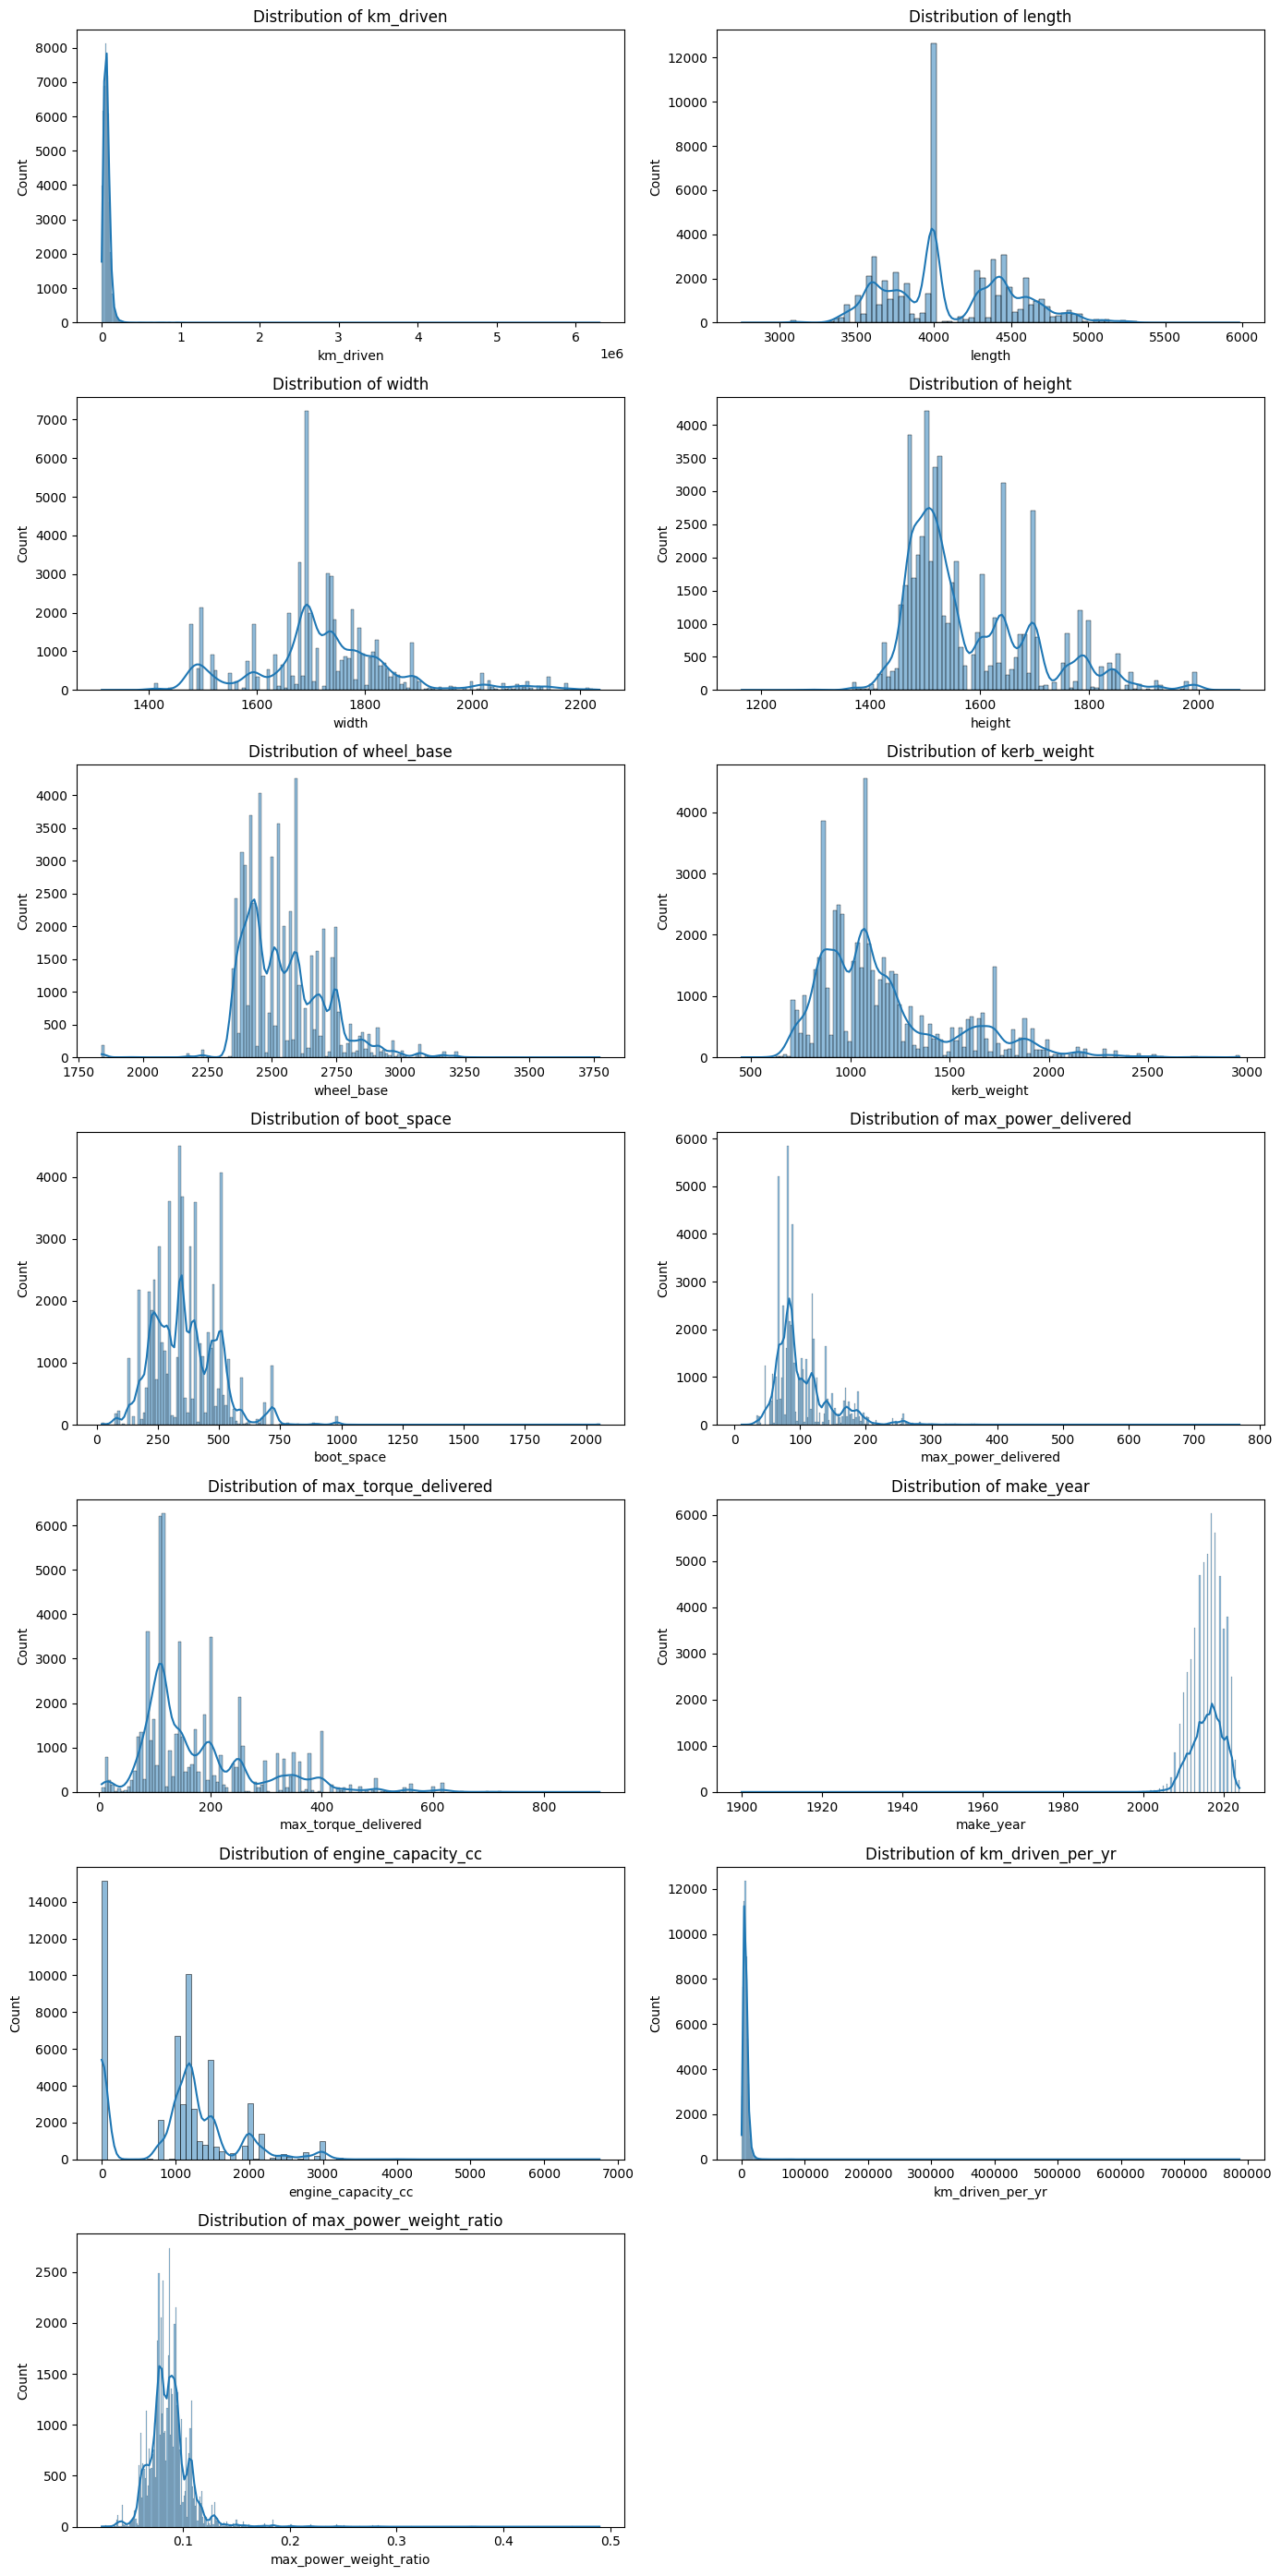

In [42]:
# Visualize the continous numerical columns using Histogram
no_of_rows = int((len(cont_num_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cont_num_cols):
    sns.histplot(data=df, x=col, ax=axes[i], kde=True)
    axes[i].set_title(f'Distribution of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

1. km_driven is highly right-skewed, with most vehicles having driven less than 3 lakh km. A few observations extend beyond 60 lakh km and should be investigated for possible data-quality issues.
2. length exhibits a multimodal distribution, representing different vehicle segments. A prominent spike is observed around 4000 mm, possibly reflecting the popularity of sub-4-meter vehicles in India due to favorable taxation policies.
3. width is multimodal, with most vehicles clustered around 1700 mm and a smaller group around 1500 mm, indicating different size categories of vehicles.
4. height shows a multimodal distribution with a dominant peak around 1500 mm and smaller peaks around 1650 mm and 1800 mm. A slight positive skew is observed because of taller vehicles such as SUVs and MPVs.
5. wheel_base has most observations between 2300 and 2800 mm, with multiple peaks corresponding to different vehicle segments. The distribution exhibits a slight positive skew.
6. kerb_weight is positively skewed, with most vehicles weighing between 700 and 1500 kg and a secondary concentration around 1600-1900 kg.
7. boot_space is multimodal, with the majority of vehicles having a capacity between 100 and 600 liters. A few observations exceed 1000 liters and should be validated to determine whether they represent large vehicles or measurement inconsistencies.
8. max_power_delivered and max_torque_delivered are both strongly right-skewed. Most vehicles are concentrated around 80-120 bhp power and 100-200 Nm torque, while a small number of observations correspond to high-performance vehicles with substantially higher values.
9. make_year is left skewed distribution with most of the cars having manufaturing year between 2005 and 2025 and few cars are having make_year in 1900 range, which needs further investigation.
10. engine_capacity shows rightly skewed distribution where majority of the engines ranges from 800 to 2000 cc and a few outliers. Also, there is a huge spike near 0 which means those engine capcities are in liters and needs to be converted to cc.

In [43]:
# Check for the cars with km driven more than 3 lacs & 20000 km/year
df[(df['km_driven']>300000) & (df['km_driven_per_yr']>20000)][['brand', 'model', 'variant', 'make_year',
                                                             'km_driven', 'years_old', 'km_driven_per_yr']]

,brand,model,variant,make_year,km_driven,years_old,km_driven_per_yr
49,TATA,SAFARI,Unknown,2010.0,500000.0,16.0,31250.000000
209,TOYOTA,FORTUNER,2WD,2014.0,333000.0,12.0,27750.000000
595,TATA,TIGOR,XT,2018.0,800000.0,8.0,100000.000000
634,RENAULT,DUSTER,Unknown,2015.0,760045.0,11.0,69095.000000
893,FORD,ECOSPORT,TITANIUM,2016.0,610000.0,10.0,61000.000000
...,...,...,...,...,...,...,...
34465,HYUNDAI,VERNA,SX(O),2012.0,315000.0,14.0,22500.000000
35023,HONDA,JAZZ,SV,2016.0,479000.0,10.0,47900.000000
35176,HONDA,CITY,V,2009.0,382682.0,17.0,22510.705882
35895,MAHINDRA,XUV500,W10,2016.0,995000.0,10.0,99500.000000


Assuming a typical indian personal car owner who drives 12000 km per year, we are removing the records where total run is more than 3 lacs km and per year run is more than 20000 km (considering higher side).

In [44]:
# Remove the above records
df = df[~((df['km_driven']>300000) & (df['km_driven_per_yr']>20000))]

In [45]:
# Check for engine capacities below 10
df[df['engine_capacity_cc']<10][['brand', 'model', 'variant', 'engine_capacity_cc']]

,brand,model,variant,engine_capacity_cc
7,TATA,NEXON,XMA,1.50
13,HYUNDAI,CRETA,E+,1.60
241,RENAULT,KWID,RXL,1.00
297,RENAULT,KWID,RXT,1.00
353,HYUNDAI,CRETA,E+,1.60
...,...,...,...,...
37801,TATA,NEXON,XZA+,1.50
37802,TATA,SAFARI,EX,2.20
37803,TATA,NEXON,XM,1.50
37805,TATA,NEXON,XZ+,1.50


In [46]:
# Multiply the engine capacities by 1000 to convert to cc
df['engine_capacity_cc'] = df['engine_capacity_cc'].apply(lambda x: x*1000 if x<10 else x)

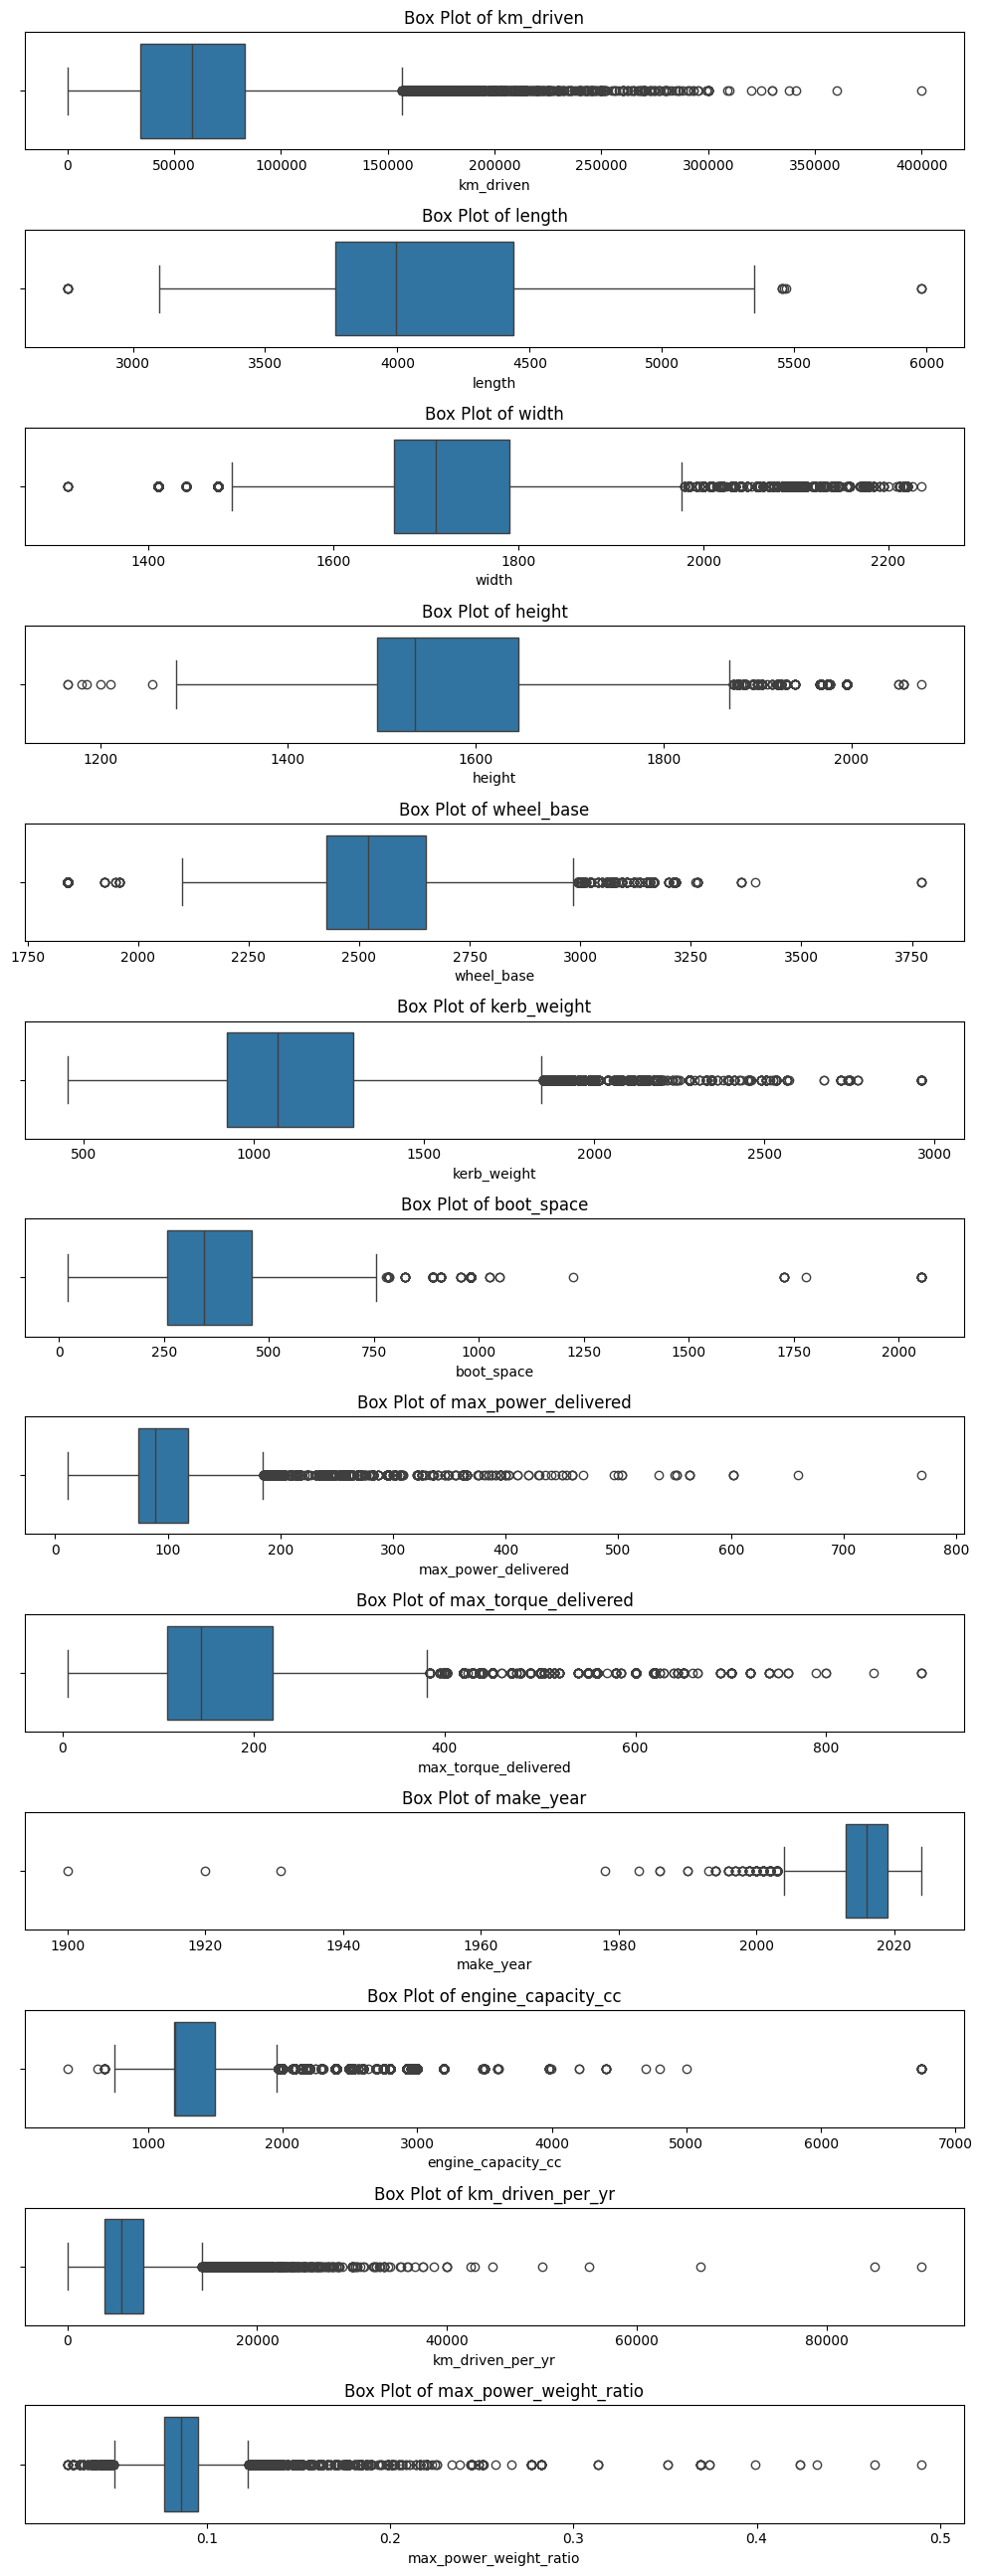

In [47]:
# Detect the outliers using boxplot
no_of_rows = len(cont_num_cols)
fig, axes = plt.subplots(no_of_rows, 1, figsize=(10, 2*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(cont_num_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Box Plot of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

In [48]:
# Investigate the outliers in lenth, width, height and wheelbase
df[((df['length']>5300) | (df['length']<3000)) | 
    ((df['height']>1900) | (df['height']<1300)) |
    ((df['wheel_base']>3000) | (df['wheel_base']<2000)) | 
    ((df['width']>2000) | (df['width']<1500))][['brand', 'model', 'variant', 'body_type', 'length', 'width', 
                                                'height', 'wheel_base']]

,brand,model,variant,body_type,length,width,height,wheel_base
29,MARUTI SUZUKI,ALTO,LXI(O),HATCHBACK,3495.0,1475.0,1460.0,2360.0
51,MARUTI SUZUKI,WAGON-R,VXI,HATCHBACK,3599.0,1495.0,1700.0,2400.0
72,MARUTI SUZUKI,ALTO-K10,LXI,HATCHBACK,3620.0,1475.0,1460.0,2360.0
97,MARUTI SUZUKI,WAGON-R,VXI+,HATCHBACK,3636.0,1475.0,1670.0,2400.0
101,MARUTI SUZUKI,WAGON-R,LXI,HATCHBACK,3599.0,1495.0,1700.0,2400.0
...,...,...,...,...,...,...,...,...
37740,MAHINDRA,SCORPIO,S10,MUV,4456.0,1820.0,1995.0,2680.0
37748,TATA,NANO,XE,HATCHBACK,3099.0,1495.0,1652.0,2230.0
37779,TATA,NANO,XT,HATCHBACK,3099.0,1495.0,1652.0,2230.0
37788,TATA,SAFARI,VX,SUV,4655.0,1965.0,1922.0,2650.0


The above records seems to be correct and can be kept for futher analysis.

In [49]:
# Investigate the outliers in kerb weight and boot space
df[(df['kerb_weight']>2000)|
    (df['boot_space']>750)][['brand', 'model', 'kerb_weight', 'boot_space']].drop_duplicates(subset=
                                                                                             ['brand', 'model'])

,brand,model,kerb_weight,boot_space
123,HYUNDAI,TUCSON,2130.0,513.0
133,TATA,SAFARI,2000.0,981.0
11,KIA,CARNIVAL,2195.0,540.0
14,MERCEDES-BENZ,GLE,2150.0,690.0
32,VOLVO,S90,2962.0,346.0
63,MERCEDES-BENZ,GLS,2455.0,680.0
113,LAND ROVER,DISCOVERY,2184.0,280.0
141,FORD,ENDEAVOUR,2394.0,430.0
162,BMW,X5,2145.0,650.0
179,MERCEDES-BENZ,M-CLASS,2175.0,690.0


There seems to have some incorrect data. Eg: The actual kerb weight of Volvo S90 ranges from 1,800 kg to 2,150 kg. The boot space of Toyota Vellfire is 148 liters etc.

In [50]:
# Correct the kerb weight and boot space
df.loc[(df['brand']=='VOLVO')&(df['model']=='S90'), 'kerb_weight'] = 2000
df.loc[(df['brand']=='TOYOTA')&(df['model']=='VELLFIRE'), 'boot_space'] = 148
df.loc[(df['brand']=='ISUZU')&(df['model']=='MU-X'), 'kerb_weight'] = 1900
df.loc[(df['brand']=='HYUNDAI')&(df['model']=='TUCSON'), 'kerb_weight'] = 1650
df.loc[(df['brand']=='MITSUBISHI')&(df['model']=='MONTERO'), 'boot_space'] = 215

In [51]:
# Investigate the outliers in maximum power and torque delivered
df[((df['max_power_delivered']>200) 
    & (df['max_torque_delivered']>400))][['brand', 'model', 'engine_capacity_cc', 
                                       'max_power_delivered', 'max_torque_delivered']].drop_duplicates(subset=
                                                                                             ['brand', 'model'])

,brand,model,engine_capacity_cc,max_power_delivered,max_torque_delivered
7,BMW,5 SERIES,2979.0,258.00,560.0
14,MERCEDES-BENZ,GLE,2998.0,201.15,500.0
63,MERCEDES-BENZ,GLS,1995.0,258.00,620.0
162,BMW,X5,2998.0,258.00,560.0
179,MERCEDES-BENZ,M-CLASS,1598.0,254.80,619.0
...,...,...,...,...,...
13069,LAND ROVER,DISCOVERY,3000.0,255.00,600.0
13286,JAGUAR,XF,3000.0,270.90,600.0
13378,JAGUAR,F-PACE,3000.0,296.00,700.0
15748,LAND ROVER,EVOQUE,2000.0,246.74,430.0


The power and torque figures seems to be correct as the luxury brands with bigger engine size are more performance oriented cars and can deliver higher power and torque.

In [52]:
# Investigate the outliers in make_year
df[df['make_year']<=1995][['brand', 'model', 'variant', 'make_year']]

,brand,model,variant,make_year
508,MAHINDRA,JEEP,Unknown,1994.0
1767,MAHINDRA,JEEP,Unknown,1990.0
6359,MARUTI SUZUKI,800,Unknown,1994.0
7401,MARUTI SUZUKI,800,Unknown,1986.0
7619,MAHINDRA,JEEP,Unknown,1994.0
11256,MARUTI SUZUKI,WAGON-R,LXI,1931.0
11388,RENAULT,TRIBER,Unknown,1900.0
11454,MAHINDRA,JEEP,Unknown,1978.0
12541,MARUTI SUZUKI,SWIFT,LXI(O),1920.0
2347,MARUTI SUZUKI,OMNI,STD,1993.0


In [53]:
# Remove the records where make year is older than 1995
df = df[~(df['make_year']<=1995)]

In [54]:
# Investigate the outliers in engine capacity
df[df['engine_capacity_cc']>3000][['brand', 'model', 
                                   'engine_capacity_cc']].drop_duplicates(subset=['brand', 'model'])

,brand,model,engine_capacity_cc
141,FORD,ENDEAVOUR,3198.0
285,BMW,7 SERIES,3982.0
331,ASTON MARTIN,VANQUISH,6749.0
520,PORSCHE,718,3604.0
807,MERCEDES-BENZ,S-CLASS,3982.0
3330,ROLLS-ROYCE,PHANTOM,6749.0
5557,BMW,M340I,3604.0
7386,MERCEDES-BENZ,CLS-CLASS,3982.0
7612,BENTLEY,FLYING SPUR,6749.0
8474,PORSCHE,PANAMERA,6749.0


The above data looks correct as the luxury car which are more performance oriented will have engines of higher capacity.

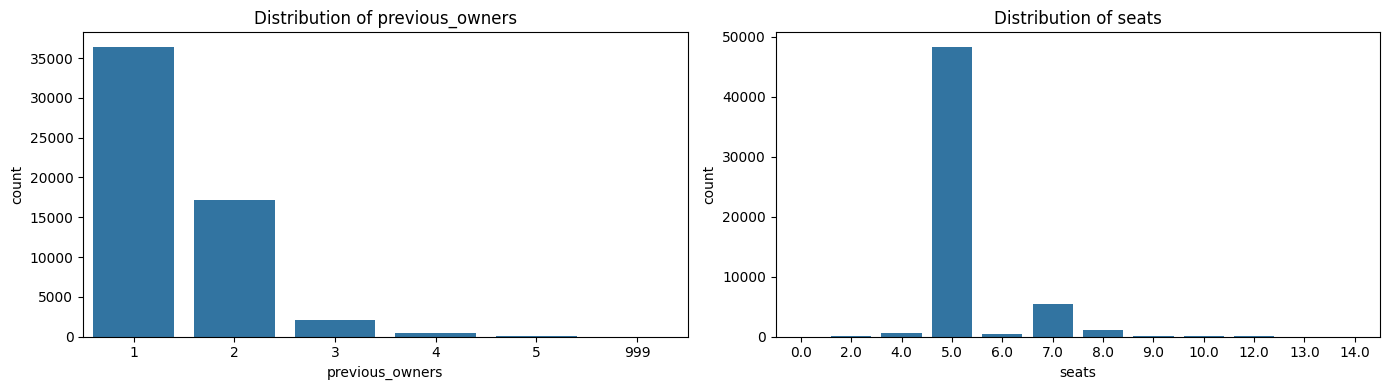

In [55]:
# Visualize the discrete numerical columns using Histogram
no_of_rows = int((len(discrete_num_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 4*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(discrete_num_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

1. The majority of the used cars have 1 previous owner, followed by 2 previous owners and 3 previous owners. A very small number of records have a value of 999, which appears to be an invalid or placeholder value rather than an actual owner count. These records require further investigation and may need to be treated as missing values or removed if confirmed to be erroneous.
2. Most vehicles in the dataset have 5 seats, followed by 7-seat vehicles. A small number of records contain 0 seats, which is likely invalid and requires investigation. Additionally, a few vehicles have seating capacities greater than 9 seats. These records should be verified to determine whether they represent genuine multi-passenger vehicles or data-quality issues.

In [55]:
# Check for records having 999 owners
df[df['previous_owners']==999]

,brand,model,variant,body_type,make_year,state,km_driven,transmission,previous_owners,fuel_type,...,steering_type,front_brake_type,rear_brake_type,boot_space,max_power_delivered,max_torque_delivered,price,years_old,km_driven_per_yr,max_power_weight_ratio
2430,MARUTI SUZUKI,EECO,AC,MINIVANS,2018.0,MAHARASHTRA,12345.0,MANUAL,999,PETROL,...,MANUAL,VENTILATED DISC,DRUM,540.0,73.00,101.0,1415000.0,8.0,1543.125,0.078664
2431,MARUTI SUZUKI,EECO,AC,MINIVANS,2018.0,MAHARASHTRA,12345.0,MANUAL,999,PETROL,...,MANUAL,VENTILATED DISC,DRUM,540.0,73.00,101.0,700000.0,8.0,1543.125,0.078664
2432,MARUTI SUZUKI,EECO,AC,MINIVANS,2018.0,MAHARASHTRA,12345.0,MANUAL,999,PETROL,...,MANUAL,VENTILATED DISC,DRUM,540.0,73.00,101.0,1150000.0,8.0,1543.125,0.078664
2620,MARUTI SUZUKI,EECO,AC,MINIVANS,2018.0,MAHARASHTRA,12345.0,MANUAL,999,PETROL,...,MANUAL,VENTILATED DISC,DRUM,540.0,73.00,101.0,1415000.0,8.0,1543.125,0.078664
4069,RENAULT,KIGER,RXZ,SUV,2022.0,DELHI,3321.0,AUTOMATIC,999,PETROL,...,POWER,DISC,DRUM,405.0,71.01,96.0,825000.0,4.0,830.250,0.070168
4225,RENAULT,KWID,CLIMBER,HATCHBACK,2022.0,DELHI,4694.0,MANUAL,999,PETROL,...,POWER,DISC,DRUM,279.0,67.00,91.0,585000.0,4.0,1173.500,0.086452
6460,SKODA,KUSHAQ,AMBITION,SUV,2022.0,WEST BENGAL,8200.0,MANUAL,999,PETROL,...,POWER,DISC,DRUM,385.0,113.98,178.0,1125000.0,4.0,2050.000,0.095381
6461,SKODA,SLAVIA,AMBITION,SEDAN,2022.0,WEST BENGAL,7300.0,MANUAL,999,PETROL,...,POWER,DISC,DRUM,521.0,113.98,178.0,1075000.0,4.0,1825.000,0.098259
11959,MG,ASTOR,SHARP,SUV,2021.0,MAHARASHTRA,19000.0,MANUAL,999,PETROL,...,POWER,DISC,DISC,346.0,108.49,144.0,1450000.0,5.0,3800.000,0.101487


There are 9 columns with 999 previous owners. These records can be removed as it will not have much effect on the entire dataset.

In [56]:
# Remove the erronous records with 999 previous owners
df = df[~(df['previous_owners']==999)]

In [57]:
# Check for records where seats is 0 or more than 9
df[(df['seats']==0)|(df['seats']>9)][['brand', 'model', 'variant', 
                                      'body_type', 'seats']].drop_duplicates(['brand', 'model'])

,brand,model,variant,body_type,seats
1931,MARUTI SUZUKI,EECO,Unknown,MINIVANS,12.0
7054,MARUTI SUZUKI,OMNI,Unknown,MINIVANS,12.0
1471,TATA,SUMO,CX,MUV,10.0
1565,CHEVROLET,TAVERA,BASE,MUV,10.0
1769,FORCE,TRAX CRUISER,CLASSIC,MUV,13.0
2126,ICML,RHINO RX,WINNER,MUV,10.0
2308,TATA,WINGER,Unknown,MINIVANS,14.0
2945,TOYOTA,QUALIS,B4,SUV,10.0
23283,TATA,INDICA,AQUA,HATCHBACK,0.0


In [58]:
# Correct the number of seats for incorrect entries
seat_mapping = {('TATA', 'INDICA'): 5, ('MARUTI SUZUKI', 'OMNI'): 8, ('MARUTI SUZUKI', 'EECO'): 8}
for (brand, model), seats in seat_mapping.items():
    df.loc[(df['brand']==brand) & (df['model']==model), 'seats'] = seats

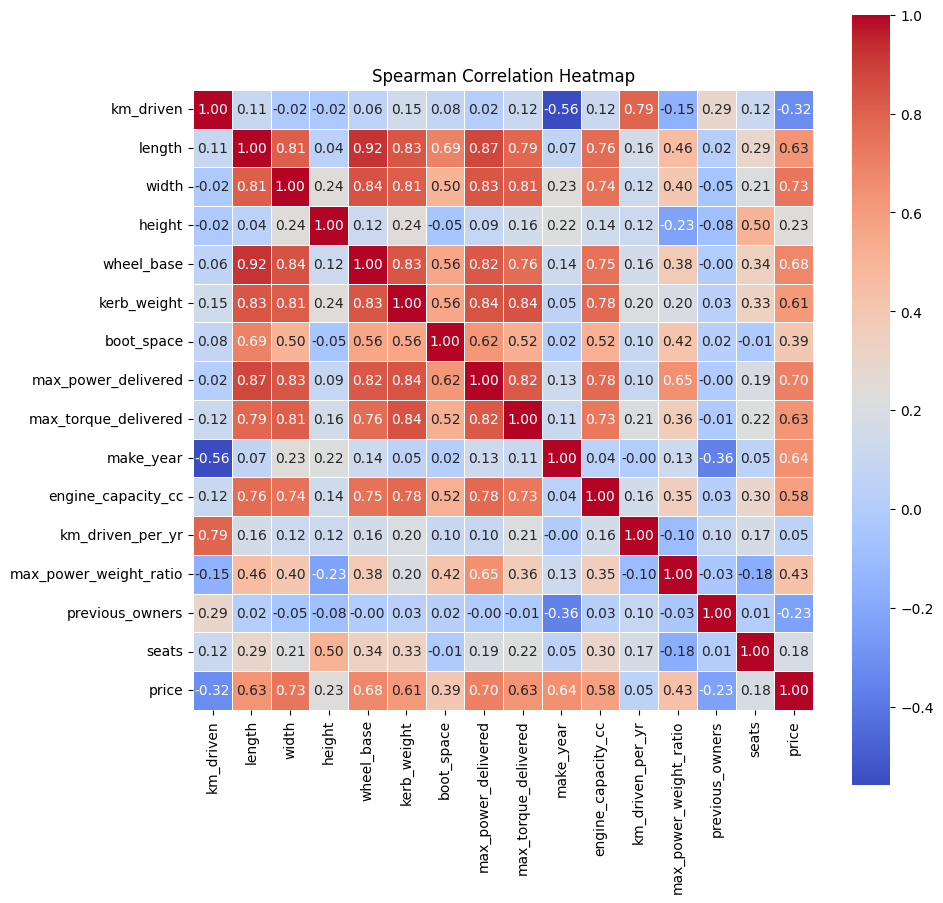

In [60]:
# Visualize the relationship of the numerical colums with the target
plt.figure(figsize=(10,10))
corr_matrix = df[cont_num_cols+discrete_num_cols+target].corr(method='spearman')
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Spearman Correlation Heatmap')
plt.show()

From the correlation heatmap, price is positively correlated with vehicle dimensions and performance-related features. The below features exhibit strong positive correlations with price:
1. Width (73%)
2. Maximum power delivered (70%)
3. Wheelbase (68%)
4. Length (63%)
5. Maximum torque delivered (63%)
6. Kerb weight (61%)
7. Make Year (64%)
8. Engine Capacity (58%)
9. Maximum power to weight ratio (43%)

This suggests that newer, larger, heavier, and more powerful vehicles generally belong to higher-priced market segments. 

In contrast, km_driven and previous ownership has a moderate negative correlation of -32% and -23% respectively  with price, indicating that higher vehicle usage tends to reduce resale value.

Additionally from the heatmap, there is very high correlation among the predictors themselves:

1. Length ↔ Power = 0.87
2. Width ↔ Power = 0.83
3. Power ↔ Torque = 0.82
4. Length ↔ Kerb Weight = 0.84
5. Wheelbase ↔ Power = 0.82

This suggests that many of these features are capturing the same underlying concept: Vehicle size and performance

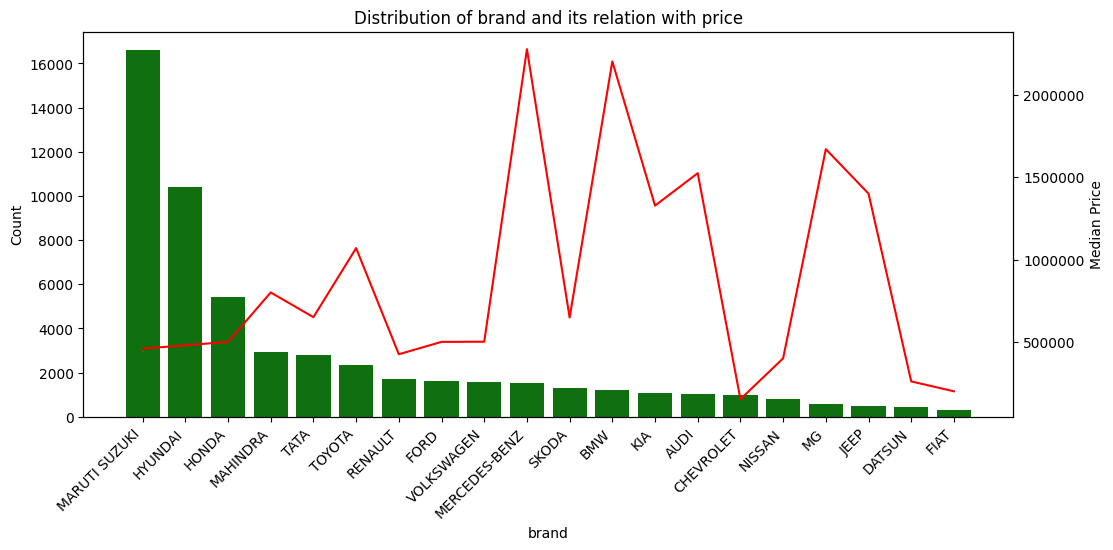

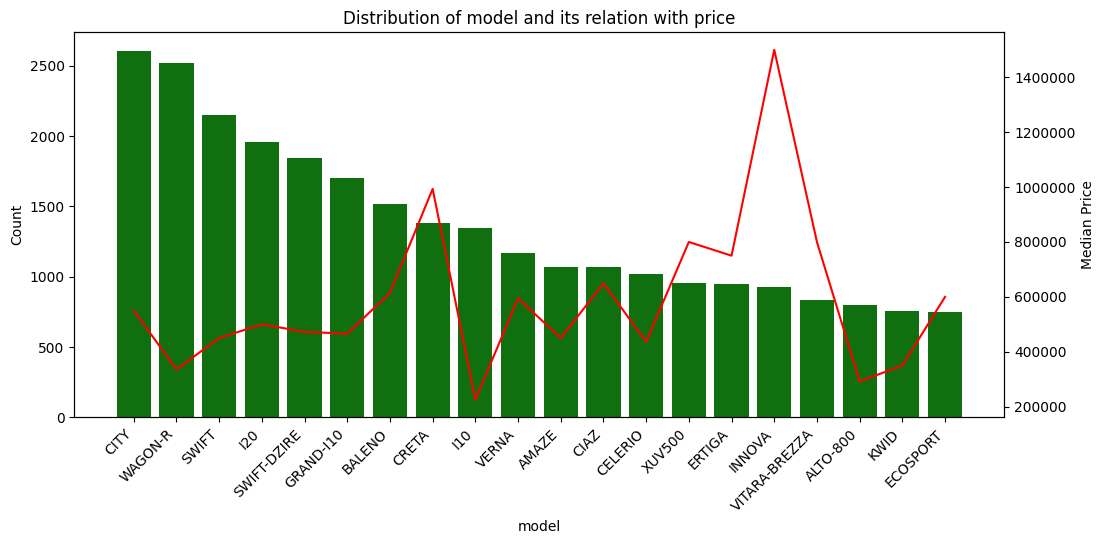

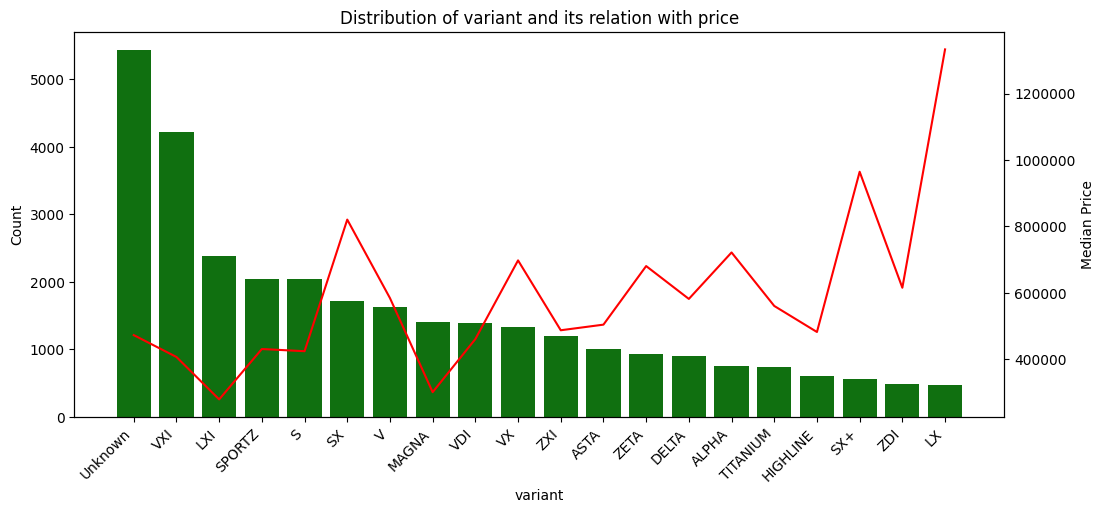

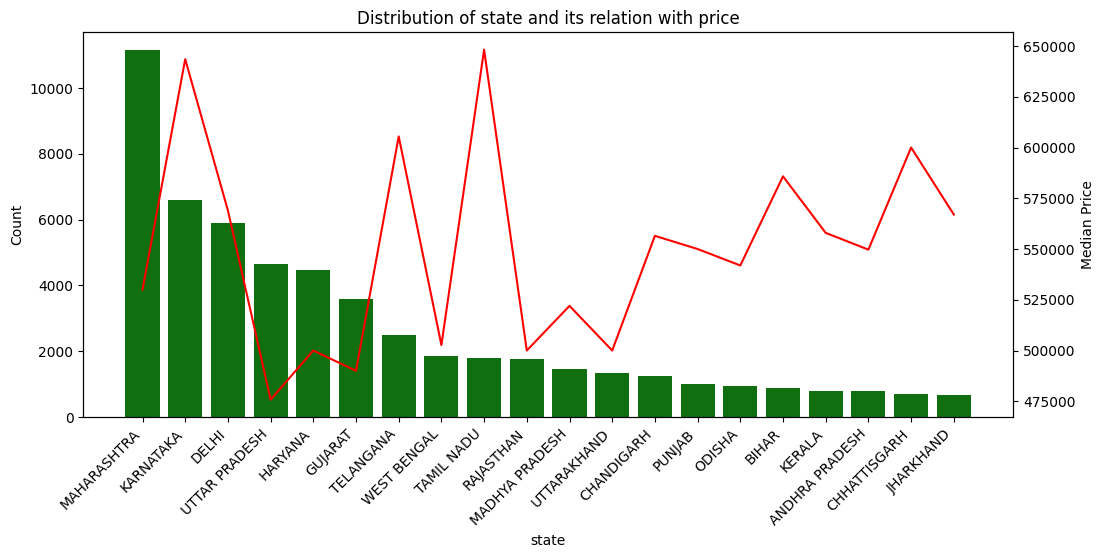

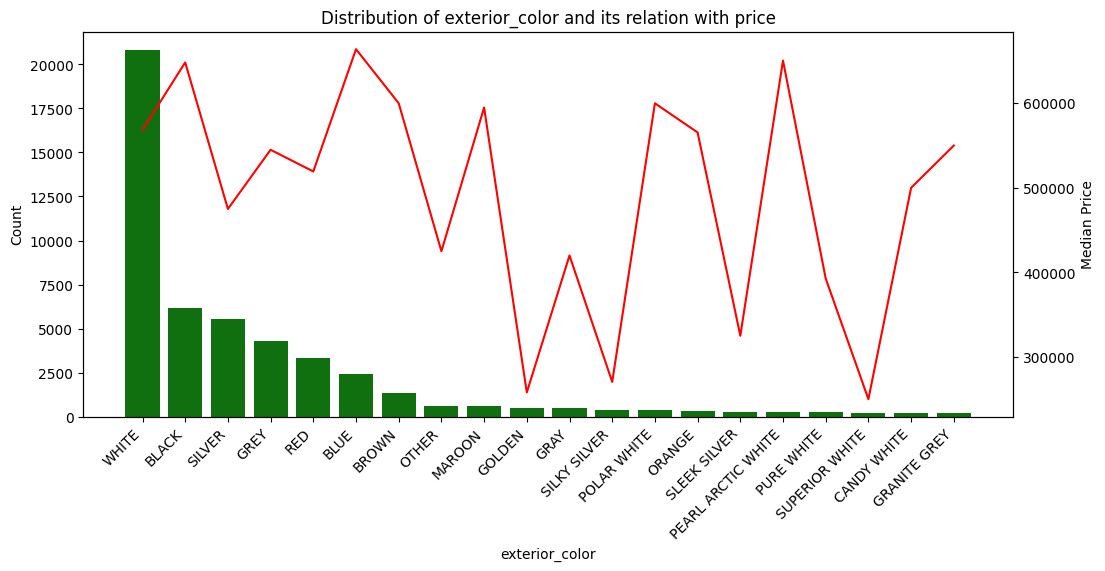

In [61]:
# Visualize the high cardinality categorical columns
for i in high_cardinality_cat_cols:
    summary = df.groupby(i).agg(median_price=('price', 'median'), 
                                car_count=('price', 'size')).sort_values('car_count', ascending=False).head(20)
    fig, ax1 = plt.subplots(figsize=(12,5))
    sns.barplot(x=summary.index, y=summary['car_count'], color='green', ax=ax1)
    ax2 = ax1.twinx()
    sns.lineplot(x=summary.index, y=summary['median_price'], color='red', ax=ax2)
    ax1.set_ylabel('Count')
    plt.setp(ax1.get_xticklabels(), rotation=45, ha='right')
    ax2.set_ylabel('Median Price')
    ax2.ticklabel_format(style='plain', axis='y')
    ax2.yaxis.get_offset_text().set_visible(False)
    plt.title(f"Distribution of {i} and its relation with price")
    plt.show()

1. MARUTI SUZUKI dominates the used-car market, followed by HYUNDAI, HONDA, MAHINDRA, and TATA. Premium brands such as Mercedes-Benz, BMW, Audi, MG, and Jeep command substantially higher median prices than mass-market brands. The brand is a strong predictor of price.

2. The most common model is City, followed by Wagon-R, Swift, and i20. Premium SUV and MPV models such as Innova, Creta, XUV500, and Vitara Brezza have significantly higher median prices than entry-level hatchbacks such as Alto 800 and Wagon-R. The model is a strong predictor of price.

3. The most common variant is "Unknown", indicating missing variant information for a large number of vehicles. Vehicle variant shows a strong relationship with price, with premium trims generally commanding higher median prices than entry-level trims. The variant is a moderately strong predictor of price.
 
4. Most used-car listings originate from Maharashtra, followed by Karnataka and Delhi. However, state-wise differences in median prices are relatively small, suggesting that geographic location has a weaker influence on vehicle price.
   
5. White is the most common exterior color. However, exterior color exhibits limited and inconsistent variation in median price, indicating a weak direct relationship with vehicle price.

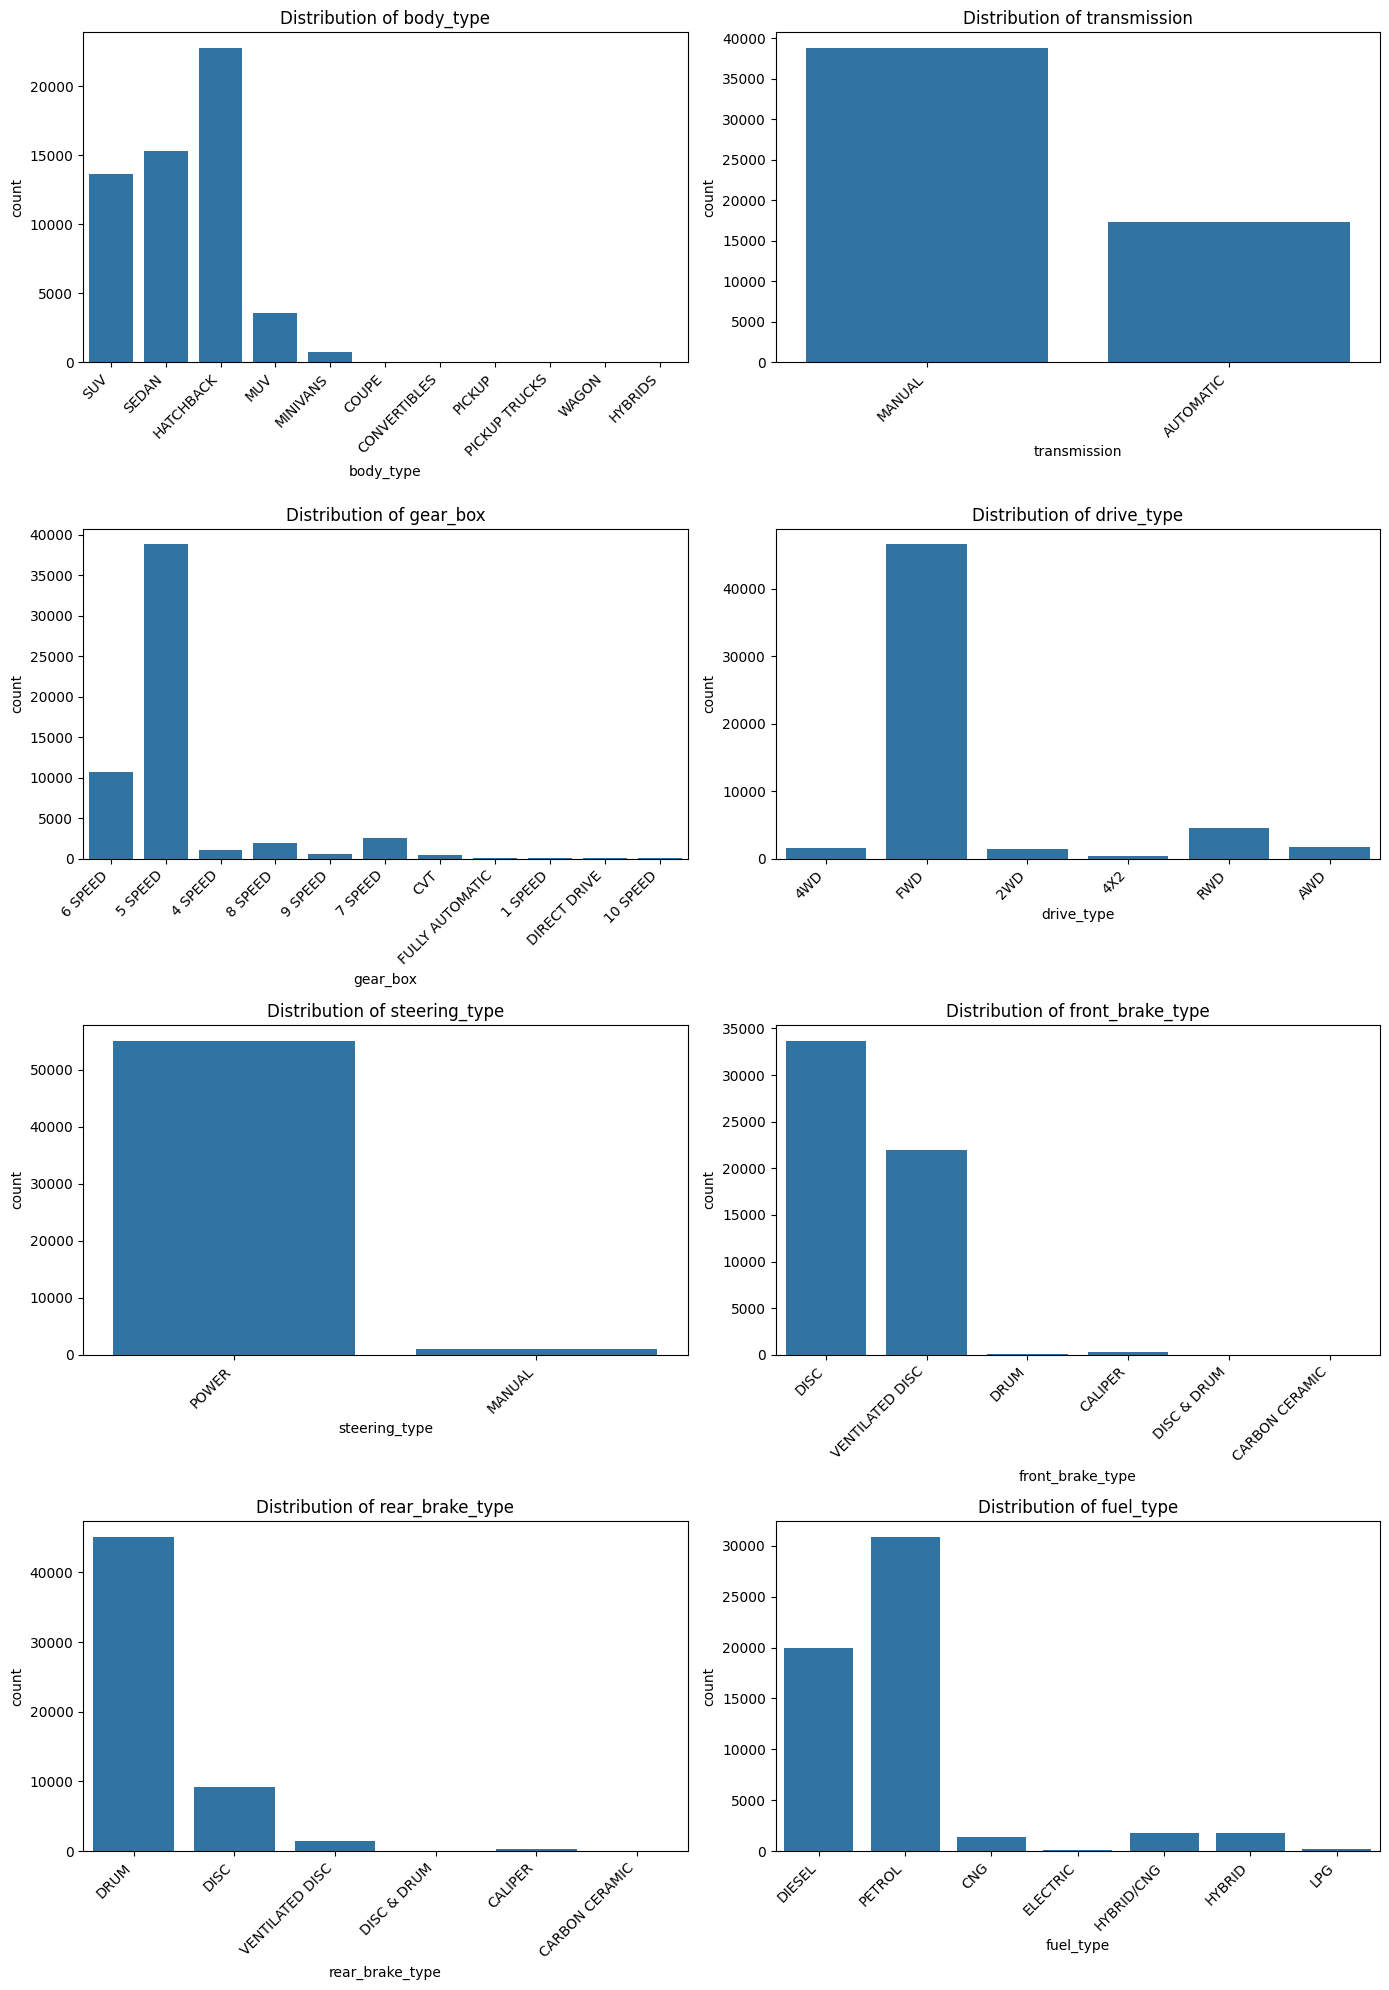

In [62]:
# Visualize the low cardinality categorical column using count plot
no_of_rows = int((len(low_cardinality_cat_cols)+1)/2)
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 5*no_of_rows))
axes = axes.flatten()
for i, col in enumerate(low_cardinality_cat_cols):
    sns.countplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')
# Remove unused subplots (if any)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

1. Hatchbacks constitute the largest segment of the used-car market, followed by sedans and SUVs. Premium body types such as coupes, convertibles, and pickup trucks are relatively rare.
2. Manual transmission vehicles dominate the market, accounting for more than twice the number of automatic vehicles.
3. 5-speed gearboxes are the most common configuration, followed by 6-speed gearboxes. Higher gearbox configurations are relatively uncommon.
4. Front-Wheel Drive (FWD) is the predominant drivetrain configuration, while AWD, 4WD, and RWD vehicles represent a small portion of the dataset.
5. Power steering is nearly universal across vehicles, while manual steering is observed in only a small number of cars, probably the very old models.
6. Disc and ventilated disc brakes in the front dominate the market, whereas drum and other brake configurations are relatively rare. However for the rear, Drum brakes are the most common followed by disc brakes. Premium brake configurations account for only a small percentage of vehicles.
7. Petrol vehicles form the largest segment, followed by diesel vehicles. Alternative fuel types such as CNG, Hybrid, Electric, and LPG represent only a small proportion of the dataset.

In [59]:
# Replace the drive type 4WD->AWD and 2WD, 4x2-> RWD
df['drive_type'] = df['drive_type'].replace({'4WD': 'AWD', '2WD': 'RWD', '4X2': 'RWD'})

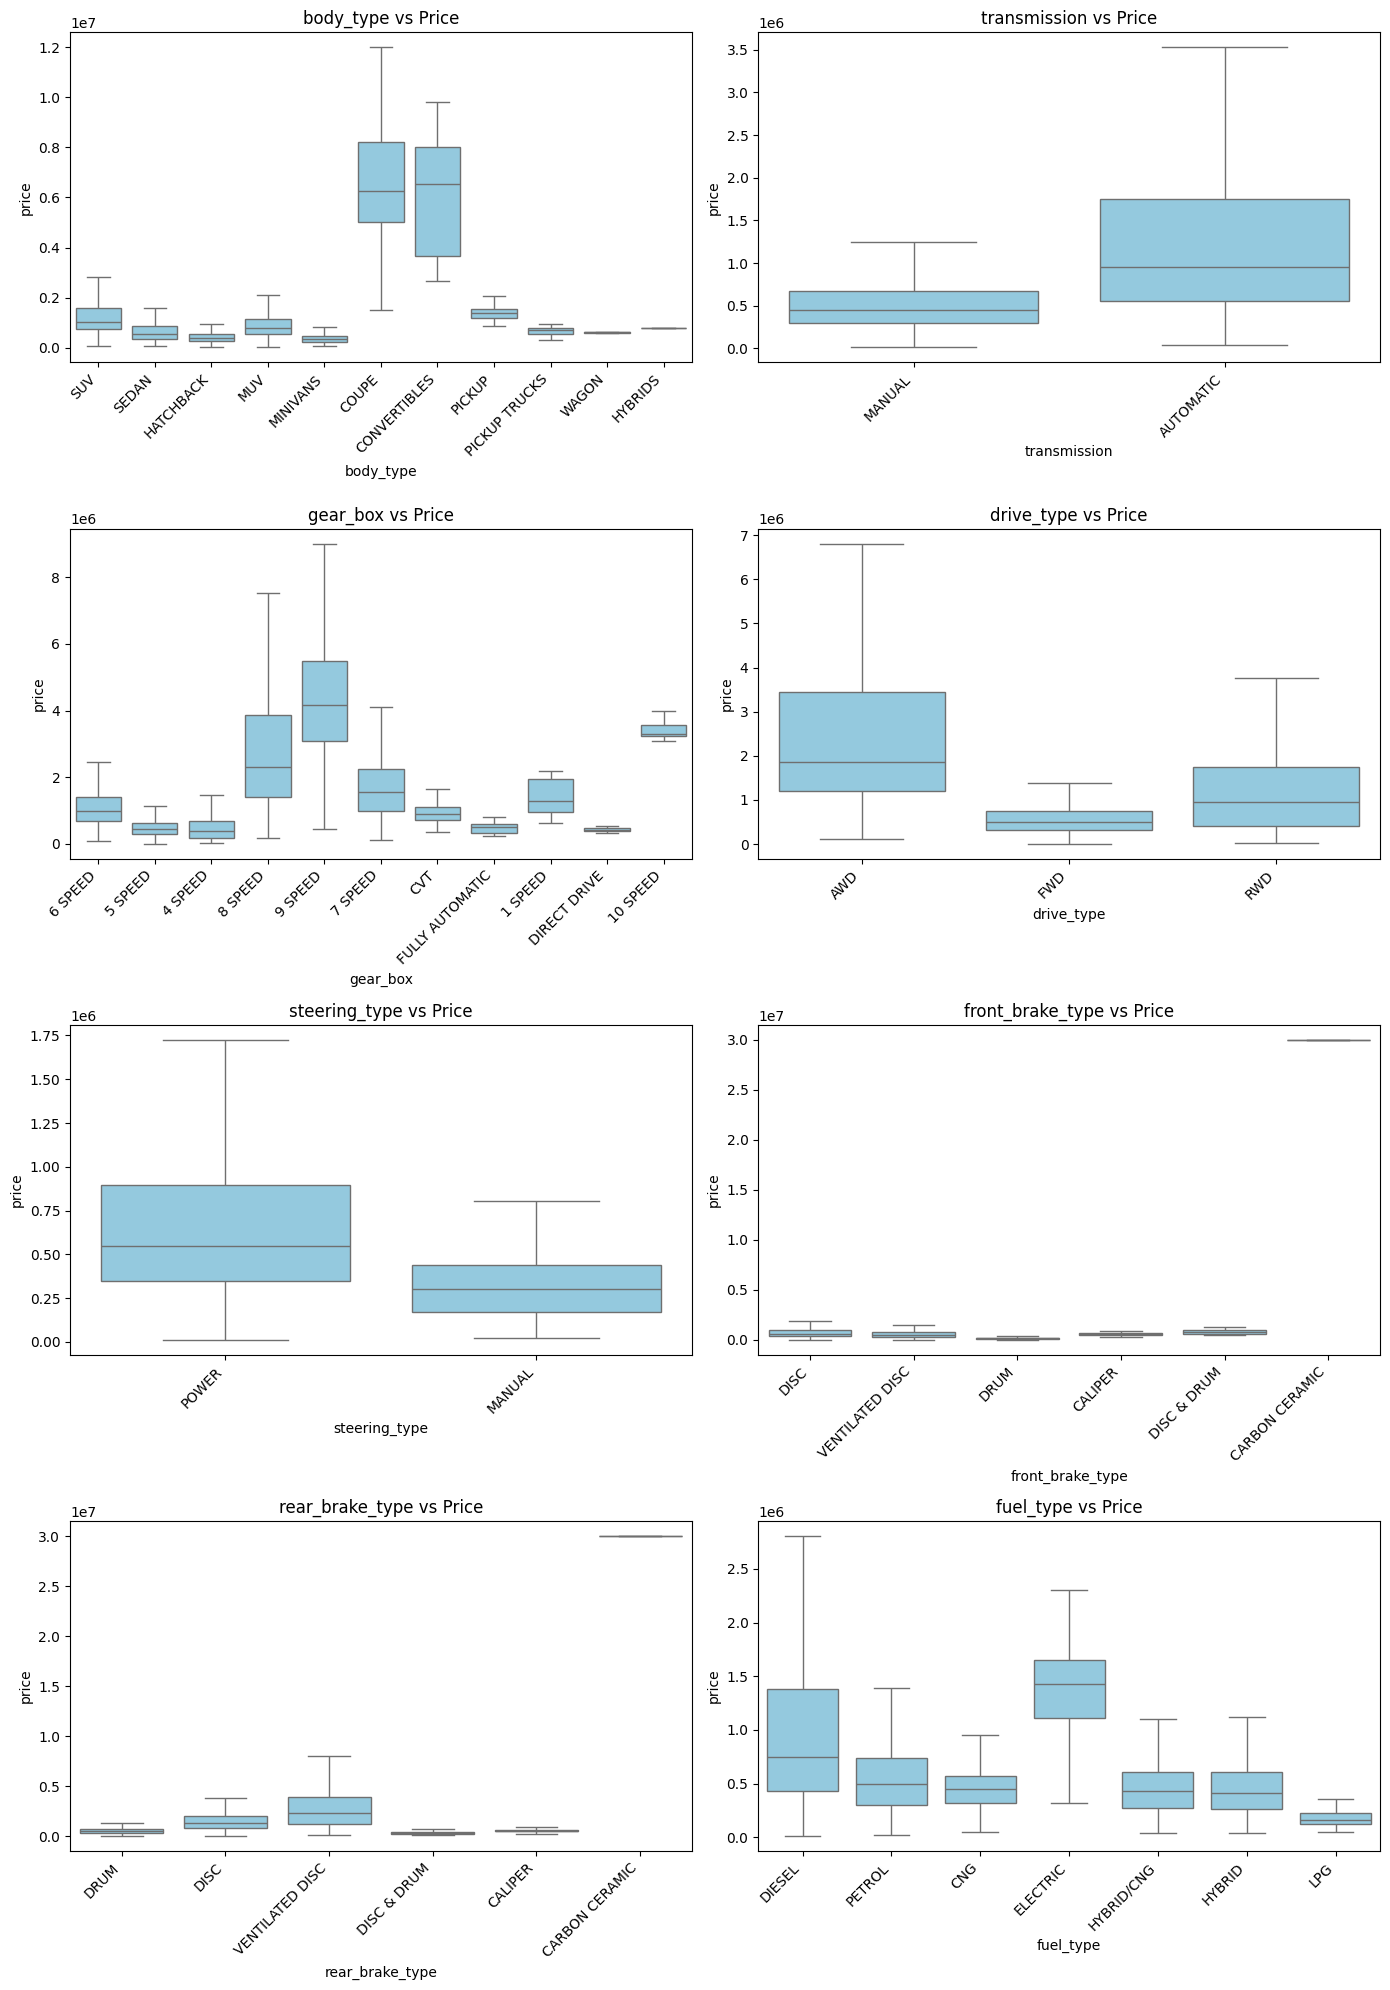

In [60]:
# Check the relationship between categorical features and price using boxplot
no_of_rows = (len(low_cardinality_cat_cols) + 1) // 2
fig, axes = plt.subplots(no_of_rows, 2, figsize=(14, 5 * no_of_rows))
axes = axes.flatten()
for i, col in enumerate(low_cardinality_cat_cols):
    sns.boxplot(data=df, x=col, y='price', showfliers=False, color='skyblue', ax=axes[i])
    axes[i].set_title(f'{col} vs Price')
    plt.setp(axes[i].get_xticklabels(), rotation=45, ha='right')
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.tight_layout()
plt.show()

1. There is a significant variation in price across body types. Hatchbacks and minivans have the lowest median prices, while coupes and convertibles command the highest prices. This indicates that body_type is likely to be a strong predictor of vehicle price.
2. Vehicles with automatic transmission have substantially higher median prices than their manual counterparts. This suggests that transmission is a strong predictor of vehicle price.
3. A noticeable variation in price is observed across gearbox configurations. Vehicles with higher gearbox configurations generally tend to have higher prices, although the relationship is not strictly linear. Therefore, gear_box appears to be a useful predictor of price.
4. AWD vehicles and vehicles equipped with power steering exhibit higher median prices than other drivetrain and steering configurations. These features show a moderate relationship with price.
5. Brake type shows a weaker relationship with price compared to other vehicle attributes. However, vehicles equipped with ventilated disc brakes at the rear generally command higher prices than those with drum brakes.
6. Fuel type has a strong influence on vehicle price. LPG vehicles have the lowest median prices, while electric vehicles have the highest median prices, with diesel and hybrid vehicles generally priced above petrol and CNG vehicles.

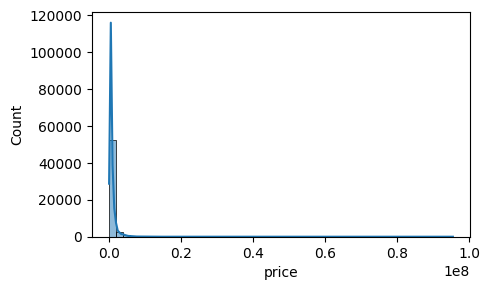

In [61]:
# Check the distribution of target feature
plt.figure(figsize=(5,3))
sns.histplot(data=df, x="price", bins=50, kde=True)
plt.tight_layout()
plt.show()

As the target feature is highly right skewed, logarithmic transformation will be used so the model is not dominated by highly proced luxury cars.

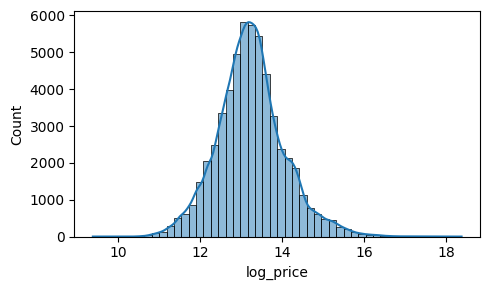

In [62]:
# Check the distribution of target feature with log transformation
df['log_price'] = np.log1p(df['price'])
plt.figure(figsize=(5,3))
sns.histplot(data=df, x="log_price", bins=50, kde=True)
plt.tight_layout()
plt.show()

The logarithmic transformed price shows a normal distribution with peak at th logarithmic price of 13 which represents the actual price of Rs 4.5 lacs.

In [63]:
# Features to keep
features_to_keep = ['brand', 'model', 'variant', 'make_year', 'km_driven', 'body_type', 'transmission', 
                    'gear_box', 'drive_type', 'steering_type', 'fuel_type', 'length', 'width', 'wheel_base', 
                    'kerb_weight', 'max_power_delivered', 'max_torque_delivered', 'engine_capacity_cc', 
                    'previous_owners', 'rear_brake_type', 'price']

In [64]:
# Select the final features of the dataset
df_final = df[features_to_keep]
df_final.head()

,brand,model,variant,make_year,km_driven,body_type,transmission,gear_box,drive_type,steering_type,...,length,width,wheel_base,kerb_weight,max_power_delivered,max_torque_delivered,engine_capacity_cc,previous_owners,rear_brake_type,price
0,MAHINDRA,THAR,LX,2020.0,11003.0,SUV,MANUAL,6 SPEED,AWD,POWER,...,3985.0,1855.0,2450.0,1685.0,150.00,300.0,2184.0,1,DRUM,1231000.0
1,HYUNDAI,VERNA,SX,2018.0,66936.0,SEDAN,MANUAL,6 SPEED,FWD,POWER,...,4375.0,1700.0,2570.0,1173.0,121.30,154.9,1591.0,1,DRUM,786000.0
2,TATA,HARRIER,XT+,2022.0,27990.0,SUV,MANUAL,6 SPEED,FWD,POWER,...,4598.0,1894.0,2741.0,1852.0,167.67,350.0,1956.0,1,DRUM,1489000.0
3,HONDA,CITY,V,2023.0,5061.0,SEDAN,AUTOMATIC,5 SPEED,FWD,POWER,...,4440.0,1695.0,2600.0,1095.0,117.30,145.0,1498.0,1,DRUM,1227000.0
4,FORD,ECOSPORT,TITANIUM,2021.0,23480.0,SUV,MANUAL,5 SPEED,FWD,POWER,...,3999.0,1765.0,2520.0,1290.0,98.96,204.0,1498.0,1,DRUM,887000.0


In [65]:
# Check and remove any duplicate records
dup = df_final.duplicated().sum()
print('Duplicate records :', dup)
if dup>0:
    df_final.drop_duplicates(inplace=True)
    dup1 = df_final.duplicated().sum()
    print('Duplicate records after removal:', dup1)

Duplicate records : 299
Duplicate records after removal: 0


### Data Preprocessing

In [66]:
# Define features and target
x = df_final.drop(['price'], axis=1)
y = df_final['price']

In [67]:
# Define the columns for encoding and standard scaling
col_to_scale = [x for x in cont_num_cols+discrete_num_cols if x in df_final.columns]
col_to_encode = [x for x in low_cardinality_cat_cols+high_cardinality_cat_cols if x in df_final.columns]

In [68]:
# Create price groups for stratified splitting
price_bins = pd.qcut(y, q=10, labels=False, duplicates="drop")

In [69]:
# Train Test Split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=price_bins)

In [70]:
# Build the preprocessing pipeline
numerical_transformer = Pipeline(steps=[("scaler", StandardScaler())])
categorical_transformer = Pipeline(steps=[("onehot", OneHotEncoder(handle_unknown="ignore", 
                                                                   sparse_output=True, dtype=np.float32))])
prepr = ColumnTransformer(transformers=[("numerical", numerical_transformer, col_to_scale), 
                                        ("categorical", categorical_transformer, col_to_encode)],
                          remainder="drop", sparse_threshold=1.0)

### Model Training

#### 1. Linear Regression

In [71]:
# Train the model with Linear Regression
lr_pipeline = Pipeline([('preprocessor', prepr), ('regressor', LinearRegression())])
lr = TransformedTargetRegressor(regressor=lr_pipeline, func=np.log1p, inverse_func=np.expm1)
lr.fit(x_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...egression())])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['brand','model','variant',...,'engine_capacity_cc','previous_owners', 'rear_brake_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,20
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...egression())])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"


In [72]:
# Train the model with Random Forest Regression
rf_pipeline = Pipeline([('preprocessor', prepr), 
                        ('regressor', RandomForestRegressor(n_estimators=300, min_samples_split=5, 
                                                            min_samples_leaf=2, max_features=0.7, 
                                                            random_state=42, max_depth=8, n_jobs=-1))])
rf = TransformedTargetRegressor(regressor=rf_pipeline, func=np.log1p, inverse_func=np.expm1)
rf.fit(x_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...m_state=42))])
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['brand','model','variant',...,'engine_capacity_cc','previous_owners', 'rear_brake_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,20
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...m_state=42))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"


In [73]:
# Train the model with XG Boost Regression
xgb_pipeline = Pipeline([('preprocessor', prepr), 
                         ('regressor', XGBRegressor(objective="reg:squarederror", n_estimators=1000, 
                                                    learning_rate=0.05, max_depth=8, min_child_weight=5, 
                                                    subsample=0.80, colsample_bytree=0.80, reg_alpha=0.10, 
                                                    tree_method="hist", random_state=42, n_jobs=-1))])
xgb = TransformedTargetRegressor(regressor=xgb_pipeline, func=np.log1p, inverse_func=np.expm1)
xgb.fit(x_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...=None, ...))])"
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['brand','model','variant',...,'engine_capacity_cc','previous_owners', 'rear_brake_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,20
regressor_ regressor_: objectFitted regressor.,Pipeline,"Pipeline(step...=None, ...))])"
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"


### Model Evaluation

In [211]:
# Create a function to predict the scores and evaluate results
results = []
def evaluation(models):
    for model_name, model in models.items():
        # Predict the results
        y_pred = model.predict(x_test)
        y_train_pred = model.predict(x_train)
    
        # Calculate the required parameters
        mae = mean_absolute_error(y_test, y_pred)
        medae = median_absolute_error(y_test, y_pred)
        rmse = root_mean_squared_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        train_r2 = r2_score(y_train, y_train_pred)
    
        # Calculate the Root Mean Squared Error on logarithmic scale
        y_pred_positive = np.maximum(y_pred, 0)
        rmsle = root_mean_squared_log_error(y_test, y_pred_positive)
    
        # Calculate cross validation scores & standard deviation
        cv = KFold(n_splits=5, shuffle=True, random_state=42)
        cv_scores = cross_validate(model, x_train, y_train, cv=cv, 
                                   scoring={'r2': 'r2', 'rmse': 'neg_root_mean_squared_error'}, n_jobs=1)
        cv_r2 = cv_scores['test_r2']
        cv_rmse = -cv_scores['test_rmse']
    
        # Check for Overfitting
        train_cv_gap = train_r2-cv_r2.mean()
        cv_test_gap = cv_r2.mean()-r2
        overfit = ('Significant Overfit' if train_cv_gap>0.15 else 'Moderate Overfit' if train_cv_gap>0.075 else 
                   'Test Set Sensitivity' if cv_test_gap>0.1 else 'No Overfit')
    
        # Return the results in a dictionary
        results.append({'Model': model_name, 'Mean AE': round(mae,2), 'Median AE': round(medae,2), 
                        'RMSE': round(rmse,2), 'CV RMSE': f"{cv_rmse.mean():.2f} ± {cv_rmse.std():.2f}", 
                        'RMS Log Error': round(rmsle,2), 'Test R² Score': round(r2,2), 
                        'CV R² Score': f"{cv_r2.mean():.2f} ± {cv_r2.std():.2f}", 
                        'Train R² Score': round(train_r2,2), 'Overfitting': overfit})
    return pd.DataFrame(results)

In [212]:
# Evaluate the results for all the trained models
trained_models = {'Linear Regression': lr, 'Random Forest Regressor': rf, 'XG Boost Regressor': xgb}
evaluation(trained_models)

,Model,Mean AE,Median AE,RMSE,CV RMSE,RMS Log Error,Test R² Score,CV R² Score,Train R² Score,Overfitting
0,Linear Regression,132054.63,61189.70,642469.34,467536.43 ± 54652.34,0.23,0.79,0.84 ± 0.03,0.95,Moderate Overfit
1,Random Forest Regressor,152180.92,66817.98,868036.18,541239.91 ± 96002.57,0.24,0.62,0.79 ± 0.06,0.84,Test Set Sensitivity
2,XG Boost Regressor,110809.84,51703.98,641953.00,437645.55 ± 91461.88,0.21,0.79,0.86 ± 0.04,0.97,Moderate Overfit


In [215]:
# Create a function to evaluate segment wise performance
segment_results = []
def segment_evaluation(models):
    p95 = y_train.quantile(0.95)
    p99 = y_train.quantile(0.99)
    segments = {'Regular (<=P95)': y_test<=p95, 'Premium/Luxury (P95-P99)': (y_test>p95) & (y_test<=p99),
                'Extreme Luxury (>P99)': y_test>p99}
    
    for model_name, model in models.items():
        y_pred = model.predict(x_test)
        for segment, mask in segments.items():
            actual = y_test[mask]
            predicted = y_pred[mask]
            segment_results.append({'Model': model_name, 'Segment': segment, 'Test Records': mask.sum(),
                                    'MAE': round(mean_absolute_error(actual, predicted), 2),
                                    'Median AE': round(median_absolute_error(actual, predicted), 2),
                                    'RMSE': round(root_mean_squared_error(actual, predicted), 2)})
    return pd.DataFrame(segment_results)

In [216]:
# Evaluate the segment wise results for all the trained models
segment_evaluation(trained_models)

,Model,Segment,Test Records,MAE,Median AE,RMSE
0,Linear Regression,Regular (<=P95),10640,93361.22,57550.41,425928.84
1,Linear Regression,Premium/Luxury (P95-P99),470,541933.64,425313.18,698228.93
2,Linear Regression,Extreme Luxury (>P99),115,2036878.68,949185.07,4638133.31
3,Random Forest Regressor,Regular (<=P95),10640,99465.49,62608.64,231041.75
4,Random Forest Regressor,Premium/Luxury (P95-P99),470,682429.71,600062.21,830362.48
5,Random Forest Regressor,Extreme Luxury (>P99),115,2862400.93,1613999.84,8111107.37
6,XG Boost Regressor,Regular (<=P95),10640,78629.12,49044.20,308948.17
7,XG Boost Regressor,Premium/Luxury (P95-P99),470,439917.24,323731.38,592220.14
8,XG Boost Regressor,Extreme Luxury (>P99),115,1743178.23,651304.50,5473609.29


XGBoost emerged as the best-performing model, with the lowest MAE (₹110.8K), Median AE (₹51.7K), RMSLE (0.21), and a Test R² of 0.79. It also performed substantially better than Linear Regression and Random Forest for premium and extreme-luxury cars. Higher errors in the extreme-luxury segment are primarily associated with the limited representation of such vehicles in the dataset. As these are legitimate observations, they are retained and evaluated separately rather than removed as outliers. XGBoost will therefore be taken forward for further regularization and hyperparameter tuning.

### Hyperparameter Tuning

Based on your current XGBoost results, the tuning objective should be reducing overfitting and increase the Test R² score.

In [208]:
# Using Randomized Search CV, tune the XG Boost model
param_distributions = {'regressor__regressor__n_estimators': [400, 600, 800, 1000],
                       'regressor__regressor__learning_rate': [0.02, 0.03, 0.05, 0.08],
                       'regressor__regressor__max_depth': [3, 4, 5, 6, 8],
                       'regressor__regressor__min_child_weight': [3, 5, 8, 10],
                       'regressor__regressor__gamma': [0, 0.05, 0.1, 0.2],
                       'regressor__regressor__subsample': [0.7, 0.8, 0.9, 1.0],
                       'regressor__regressor__colsample_bytree': [0.7, 0.8, 0.9, 1.0],
                       'regressor__regressor__reg_alpha': [0, 0.1, 0.5, 1.0],
                       'regressor__regressor__reg_lambda': [1, 2, 5, 10]}
xgb_random_search = RandomizedSearchCV(estimator=xgb, param_distributions=param_distributions, n_iter=30,
                                       scoring='neg_mean_absolute_error', cv=cv, random_state=42, n_jobs=-1,
                                       verbose=2, return_train_score=True)
xgb_random_search.fit(x_train, y_train)
print("Best Parameters:", xgb_random_search.best_params_)
print("\nBest CV MAE:",-xgb_random_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters: {'regressor__regressor__subsample': 0.8, 'regressor__regressor__reg_lambda': 1, 'regressor__regressor__reg_alpha': 0, 'regressor__regressor__n_estimators': 800, 'regressor__regressor__min_child_weight': 5, 'regressor__regressor__max_depth': 8, 'regressor__regressor__learning_rate': 0.05, 'regressor__regressor__gamma': 0.05, 'regressor__regressor__colsample_bytree': 0.9}

Best CV MAE: 112691.28007001682


In [210]:
# Train the tuned XG Boost model
xgb_tuned_pipeline = Pipeline([('preprocessor', prepr), 
                         ('regressor', XGBRegressor(objective="reg:squarederror", n_estimators=800, 
                                                    learning_rate=0.05, max_depth=8, min_child_weight=5, 
                                                    subsample=0.8, colsample_bytree=0.9, gamma=0.05,
                                                    tree_method="hist", random_state=42, n_jobs=-1))])
xgb_tuned = TransformedTargetRegressor(regressor=xgb_tuned_pipeline, func=np.log1p, inverse_func=np.expm1)
xgb_tuned.fit(x_train, y_train)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","Pipeline(step...=None, ...))])"
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](20,)","['brand','model','variant',...,'engine_capacity_cc','previous_owners', 'rear_brake_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,20
regressor_ regressor_: objectFitted regressor.,Pipeline,"Pipeline(step...=None, ...))])"
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"


In [213]:
# Evaluate the tuned XG Boost Model
tuned_model = {'Tuned XGBoost Regressor': xgb_tuned}
evaluation(tuned_model)

,Model,Mean AE,Median AE,RMSE,CV RMSE,RMS Log Error,Test R² Score,CV R² Score,Train R² Score,Overfitting
0,Linear Regression,132054.63,61189.70,642469.34,467536.43 ± 54652.34,0.23,0.79,0.84 ± 0.03,0.95,Moderate Overfit
1,Random Forest Regressor,152180.92,66817.98,868036.18,541239.91 ± 96002.57,0.24,0.62,0.79 ± 0.06,0.84,Test Set Sensitivity
2,XG Boost Regressor,110809.84,51703.98,641953.00,437645.55 ± 91461.88,0.21,0.79,0.86 ± 0.04,0.97,Moderate Overfit
3,Tuned XGBoost Regressor,113882.63,52424.11,690816.28,436571.64 ± 92335.20,0.21,0.76,0.86 ± 0.04,0.96,Moderate Overfit


In [225]:
# Evaluate the segment wise results for the tuned model
segment_evaluation(tuned_model)
pd.pivot_table(data=segment_evaluation(tuned_model), columns=['Segment', 'Test Records'], index='Model')

MAE                           \
Segment                 Extreme Luxury (>P99) Premium/Luxury (P95-P99)   
Test Records                            115                      470     
Model                                                                    
Linear Regression                  2036878.68                541933.64   
Random Forest Regressor            2862400.93                682429.71   
Tuned XGBoost Regressor            1831652.31                457021.36   
XG Boost Regressor                 1743178.23                439917.24   

                                                    Median AE  \
Segment                 Regular (<=P95) Extreme Luxury (>P99)   
Test Records                      10640                 115     
Model                                                           
Linear Regression              93361.22             949185.07   
Random Forest Regressor        99465.49            1613999.84   
Tuned XGBoost Regressor        80159.07             682591.00   
XG Boost Regressor             78629.12             651304.50   

                                                                  \
Segment                 Premium/Luxury (P95-P99) Regular (<=P95)   
Test Records                               470             10640   
Model                                                              
Linear Regression                      425313.18        57550.41   
Random Forest Regressor                600062.21        62608.64   
Tuned XGBoost Regressor                346529.62        49572.62   
XG Boost Regressor                     323731.38        49044.20   

                                         RMSE                           \
Segment                 Extreme Luxury (>P99) Premium/Luxury (P95-P99)   
Test Records                            115                      470     
Model                                                                    
Linear Regression                  4638133.31                698228.93   
Random Forest Regressor            8111107.37                830362.48   
Tuned XGBoost Regressor            5930611.57                611741.56   
XG Boost Regressor                 5473609.29                592220.14   

                                         
Segment                 Regular (<=P95)  
Test Records                      10640  
Model                                    
Linear Regression             425928.84  
Random Forest Regressor       231041.75  
Tuned XGBoost Regressor       326779.39  
XG Boost Regressor            308948.17

### Model Conclusion

Three regression algorithms, Linear Regression, Random Forest Regressor, and XGBoost Regressor, were evaluated using MAE, Median Absolute Error, RMSE, RMSLE, R², cross-validation performance, train-test generalization, and price-segment-level errors. XGBoost was subsequently optimized using RandomizedSearchCV to determine whether hyperparameter tuning could further improve its performance.

The original XGBoost model provided the best overall predictive performance. It achieved an MAE of ₹110,809.84, Median Absolute Error of ₹51,703.98, RMSLE of 0.21, Test R² of 0.79, and CV R² of 0.86 ± 0.04. Although Linear Regression achieved a nearly identical Test R² of 0.79, XGBoost produced substantially lower MAE and Median Absolute Error, making its predictions more accurate for the typical vehicle.

The segment-wise evaluation further strengthened the selection of XGBoost. It produced the lowest MAE and Median Absolute Error across all three price segments, including regular, premium/luxury, and extreme-luxury vehicles. For the extreme-luxury segment, XGBoost achieved an MAE of approximately ₹17.43 lakh, compared with ₹20.37 lakh for Linear Regression and ₹28.62 lakh for Random Forest.

Hyperparameter tuning did not improve generalization. The tuned XGBoost model increased MAE from ₹110,809.84 to ₹113,882.63, increased RMSE from ₹641,953 to ₹690,816, and reduced Test R² from 0.79 to 0.76. Segment-wise performance also deteriorated slightly. Therefore, the tuned model was rejected in favor of the original XGBoost configuration.

The dataset contains a small number of valid ultra-luxury vehicles, including the ₹9.55 crore Rolls-Royce Phantom. These observations were intentionally retained rather than removed as statistical outliers because they represent legitimate vehicles. Their limited representation explains the substantially larger errors observed above the 99th price percentile. MAE, Median AE, RMSLE, and segment-level evaluation were therefore considered alongside RMSE to prevent a handful of extreme-price observations from disproportionately influencing model selection.

Final Model: XGBoost Regressor. Despite some remaining train-validation gap, it offers the strongest balance of overall accuracy, cross-validation performance, relative prediction error, and performance across different vehicle price segments.

### Model Deployment

In [87]:
# Save the model
joblib.dump(xgb, 'car_price_predictor.pkl')

['car_price_predictor.pkl']

In [88]:
# Create a function to fetch the mode of a given series
def get_mode(series):
    modes = series.mode()
    if not modes.empty:
        return modes.iloc[0]
    return series.iloc[0]

In [89]:
# Build vehicle specification lookup table
lookup_keys = ['brand', 'model', 'variant', 'fuel_type', 'transmission']
user_input_cols = ['brand', 'model', 'variant', 'make_year', 'km_driven', 'previous_owners', 'fuel_type', 
                   'transmission']
auto_fetch_cols = ['body_type', 'gear_box', 'drive_type', 'steering_type', 'length', 'width', 'wheel_base', 
                   'kerb_weight', 'max_power_delivered', 'max_torque_delivered', 'engine_capacity_cc', 
                   'rear_brake_type']
vehicle_lookup = df[lookup_keys + auto_fetch_cols].copy()

# If duplicate brand-model-variant combinations exist, aggregate them into one specification record.
numeric_spec_cols = ['length', 'width', 'wheel_base', 'kerb_weight', 'max_power_delivered', 
                     'max_torque_delivered', 'engine_capacity_cc']
categorical_spec_cols = ['body_type', 'gear_box', 'drive_type', 'steering_type', 'rear_brake_type']

# Aggregation rules for different types of features
aggregation_rules = {**{col: 'median' for col in numeric_spec_cols},
                     **{col: get_mode for col in categorical_spec_cols}}

vehicle_lookup = vehicle_lookup.groupby(lookup_keys, as_index=False).agg(aggregation_rules)
joblib.dump(vehicle_lookup, 'vehicle_specifications.pkl')

['vehicle_specifications.pkl']

In [90]:
# Create and save the metadata and specification lookup
deployment_metadata = {'feature_columns': x_train.columns.tolist(), 'categorical_cols': col_to_encode,
                       'numeric_cols': col_to_scale, 'user_input_cols': user_input_cols, 
                       'auto_fetch_cols': auto_fetch_cols, 
                       'categorical_values': {col: sorted(df[col].dropna().astype(str).str.strip().str.upper()
                                                                 .unique().tolist()) for col in col_to_encode},
                       'numeric_defaults': {col: float(df[col].median()) for col in col_to_scale},
                       'numeric_min': {col: float(df[col].min()) for col in col_to_scale},
                       'numeric_max': {col: float(df[col].max()) for col in col_to_scale}}

joblib.dump(deployment_metadata, 'car_price_metadata.pkl')

['car_price_metadata.pkl']